In [ ]:
from google.colab import drive
drive.mount('/content/drive')

MessageError: Error: credential propagation was unsuccessful

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
!mkdir -p /content/work
!cp /content/drive/MyDrive/confidence_project/raw_audio.zip /content/work/
!cp /content/drive/MyDrive/confidence_project/preprocess_fluency_audio.py /content/work/
%cd /content/work
!unzip -q raw_audio.zip -d raw_audio
!ls raw_audio | head

cp: cannot stat '/content/drive/MyDrive/confidence_project/raw_audio.zip': No such file or directory
/content/work
unzip:  cannot find or open raw_audio.zip, raw_audio.zip.zip or raw_audio.zip.ZIP.
ls: cannot access 'raw_audio': No such file or directory


In [ ]:
!ls /content/drive/MyDrive | head -50
!echo ---
!ls /content/drive/MyDrive/confidence_project

Colab Notebooks
confidence_project
Gowtham-CV.pdf
Gowtham-DataScience_CV.pdf
---
preprocess_fluency_audio.py  raw_audio.rar


In [ ]:
!apt-get -qq install unrar > /dev/null
!mkdir -p /content/work
!cp /content/drive/MyDrive/confidence_project/raw_audio.rar /content/work/
!cp /content/drive/MyDrive/confidence_project/preprocess_fluency_audio.py /content/work/
%cd /content/work
!mkdir -p raw_audio
!unrar x -inul raw_audio.rar raw_audio/
!ls raw_audio | head
!ls raw_audio | wc -l

/content/work
raw_audio
1


In [ ]:
!pip install -q rarfile patool
!apt-get -qq install unar > /dev/null
!unar -q -o /content/work/raw_audio /content/work/raw_audio.rar
!ls /content/work/raw_audio | head

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 102.0/102.0 kB 11.8 MB/s eta 0:00:00
E: Failed to fetch http://archive.ubuntu.com/ubuntu/pool/main/u/unbound/libunbound8_1.19.2-1ubuntu3.9_amd64.deb  404  Not Found [IP: 91.189.92.24 80]
E: Unable to fetch some archives, maybe run apt-get update or try with --fix-missing?
/bin/bash: line 1: unar: command not found
raw_audio


In [ ]:
!apt-get -qq update
!apt-get -qq install -y unrar-free > /dev/null
!which unrar-free || which unrar

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
/usr/bin/unrar-free


In [ ]:
!mkdir -p /content/work
!cp /content/drive/MyDrive/confidence_project/raw_audio.zip /content/work/
!cp /content/drive/MyDrive/confidence_project/preprocess_fluency_audio.py /content/work/
%cd /content/work
!unzip -q raw_audio.zip -d raw_audio
!ls raw_audio | head

cp: cannot stat '/content/drive/MyDrive/confidence_project/raw_audio.zip': No such file or directory
/content/work
unzip:  cannot find or open raw_audio.zip, raw_audio.zip.zip or raw_audio.zip.ZIP.
raw_audio


In [ ]:
!find /content/work/raw_audio -type f | wc -l
!ls /content/work/raw_audio/raw_audio | head

1146
1000.opus
1001.opus
1002.opus
1003.opus
1004.opus
1005.opus
1006.opus
1007.opus
1008.opus
1009.opus


In [ ]:
!pip install -q uv
!uv venv --python 3.11 /content/env
!uv pip install --python /content/env/bin/python torch==2.0.1 torchaudio==2.0.2 "numpy<2" deepfilternet

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 17.9/17.9 MB 38.7 MB/s eta 0:00:00
Using CPython 3.11.17
Creating virtual environment at: /content/env
Activate with: source /content/env/bin/activate
Using Python 3.11.17 environment at: /content/env
Resolved 36 packages in 419ms
Prepared 36 packages in 47.81s
Installed 36 packages in 325ms
 + appdirs==1.4.4
 + certifi==2026.7.22
 + charset-normalizer==3.5.2
 + cmake==4.4.4
 + deepfilterlib==0.5.6
 + deepfilternet==0.5.6
 + filelock==4.1.1
 + idna==3.20
 + jinja2==3.1.6
 + lit==23.1.3
 + loguru==0.7.3
 + markupsafe==3.0.4
 + mpmath==1.3.0
 + networkx==3.6.1
 + numpy==1.26.4
 + nvidia-cublas-cu11==11.10.3.66
 + nvidia-cuda-cupti-cu11==11.7.101
 + nvidia-cuda-nvrtc-cu11==11.7.99
 + nvidia-cuda-runtime-cu11==11.7.99
 + nvidia-cudnn-cu11==8.5.0.96
 + nvidia-cufft-cu11==10.9.0.58
 + nvidia-curand-cu11==10.2.10.91
 + nvidia-cusolver-cu11==11.4.0.1
 + nvidia-cusparse-cu11==11.7.4.91
 + nvidia-nccl-cu11==2.14.3
 + nvidia-nvtx-cu11==11.7.91
 + packag

In [ ]:
import subprocess
from pathlib import Path

src = Path("/content/work/raw_audio/raw_audio")
dst = Path("/content/work/raw_wav"); dst.mkdir(exist_ok=True)

for p in sorted(src.iterdir()):
    if p.suffix.lower() in {".wav", ".mp3", ".flac", ".ogg", ".opus", ".m4a"}:
        subprocess.run(["ffmpeg", "-hide_banner", "-loglevel", "error", "-y", "-i", str(p),
                        "-ac", "1", "-ar", "48000", str(dst/f"{p.stem}.wav")])
print(len(list(dst.glob("*.wav"))), "files")

1146 files


In [ ]:
!mkdir -p /content/work/test_in
!ls /content/work/raw_wav | head -3 | while read f; do cp "/content/work/raw_wav/$f" /content/work/test_in/; done
!/content/env/bin/deepFilter /content/work/test_in/*.wav -o /content/work/test_out --no-suffix

2026-10-12 06:43:58 | INFO     | DF | Running on torch 2.0.1+cu117
2026-10-12 06:43:58 | INFO     | DF | Running on host 4ee3945263de
fatal: not a git repository (or any of the parent directories): .git
2026-10-12 06:43:59 | INFO     | DF | Loading model settings of DeepFilterNet3
2026-10-12 06:43:59 | INFO     | DF | Using DeepFilterNet3 model at /root/.cache/DeepFilterNet/DeepFilterNet3
2026-10-12 06:43:59 | INFO     | DF | Initializing model `deepfilternet3`
2026-10-12 06:44:03 | INFO     | DF | Found checkpoint /root/.cache/DeepFilterNet/DeepFilterNet3/checkpoints/model_120.ckpt.best with epoch 120
2026-10-12 06:44:03 | INFO     | DF | Running on device cuda:0
2026-10-12 06:44:03 | INFO     | DF | Model loaded
2026-10-12 06:44:06 | INFO     | DF | 33% | Enhanced noisy audio file '1000.wav' in 2.69s (RT factor: 0.035)
2026-10-12 06:44:07 | INFO     | DF | 67% | Enhanced noisy audio file '1001.wav' in 0.49s (RT factor: 0.008)
2026-10-12 06:44:07 | INFO     | DF | 100% | Enhanced nois

In [ ]:
!pip install -q google-genai
import json, time, threading
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor
from google import genai
from google.genai import types
from google.colab import userdata

client = genai.Client(api_key=userdata.get("GEMINI_KEY"))
MODEL = "gemini-3.8-flash"
AUDIO_DIR = Path("/content/work/processed_confidence")
OUT = Path("/content/drive/MyDrive/confidence_project/simple_ratings.jsonl")

PROMPT = """You are a speech communication professor. Listen to this recording and rate the
speaker's CONFIDENCE from 0 to 10 based on vocal delivery only (pauses, hesitation, voice
steadiness, loudness, pitch variation, pace). Ignore content, accent, language, background
noise and other people's voices.
0-2 very nervous, 3-4 unsure, 5-6 average, 7-8 steady and assured, 9-10 very confident.
Use the full range. Return ONLY JSON: {"confidence_score": <number>}"""

SCHEMA = types.Schema(type="OBJECT",
    properties={"confidence_score": types.Schema(type="NUMBER")},
    required=["confidence_score"])

MIN_GAP = 13                      # free tier = 5 requests/minute
_last = [0.0]
gate = threading.Lock()

def wait_turn():
    with gate:
        d = MIN_GAP - (time.time() - _last[0])
        if d > 0:
            time.sleep(d)
        _last[0] = time.time()

def rate(path):
    audio = types.Part.from_bytes(data=path.read_bytes(), mime_type="audio/wav")
    for attempt in range(8):
        wait_turn()
        try:
            r = client.models.generate_content(
                model=MODEL, contents=[PROMPT, audio],
                config=types.GenerateContentConfig(
                    temperature=0, response_mime_type="application/json",
                    response_schema=SCHEMA))
            s = float(json.loads(r.text)["confidence_score"])
            return {"file": path.stem, "confidence_score": round(min(10, max(0, s)), 1)}
        except Exception as e:
            msg = str(e)
            if "429" in msg:
                time.sleep(60)
            elif "503" in msg:
                time.sleep(20)
            else:
                print(path.stem, "error:", msg[:100]); time.sleep(5)
    return None

done = set()
if OUT.exists():
    done = {json.loads(l)["file"] for l in OUT.open() if l.strip()}
todo = [p for p in sorted(AUDIO_DIR.glob("*.wav")) if p.stem not in done]
print("Already done:", len(done), "| To do:", len(todo))

lock = threading.Lock()
count = [0]
def work(p):
    r = rate(p)
    if r:
        with lock, OUT.open("a") as f:
            f.write(json.dumps(r) + "\n")
        count[0] += 1
        if count[0] % 20 == 0:
            print(f"{len(done) + count[0]} of {len(done) + len(todo)} rated")

with ThreadPoolExecutor(1) as ex:
    list(ex.map(work, todo))
print("Run finished. Now run Cell 2 to make the Excel file.")

Already done: 0 | To do: 0
Run finished. Now run Cell 2 to make the Excel file.


In [ ]:
import json
from openpyxl import Workbook

OUT = "/content/drive/MyDrive/confidence_project/simple_ratings.jsonl"
rows = {}
for l in open(OUT):
    if l.strip():
        d = json.loads(l); rows[d["file"]] = d["confidence_score"]

wb = Workbook(); ws = wb.active; ws.title = "confidence_scores"
ws.append(["file", "confidence_score"])
for k in sorted(rows, key=lambda x: int(x) if x.isdigit() else x):
    ws.append([k, rows[k]])
path = "/content/drive/MyDrive/confidence_project/confidence_scores.xlsx"
wb.save(path)
print(len(rows), "of 1146 rated ->", path)

FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/confidence_project/simple_ratings.jsonl'

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
!ls -lh /content/drive/MyDrive/confidence_project
!ls /content/work/processed_confidence 2>/dev/null | wc -l

Mounted at /content/drive
total 1.3G
-rw------- 1 root root  106 Oct 12 08:36 confidence_scores.csv
-rw------- 1 root root 2.9K Oct 12 09:09 confidence_scores.xlsx
-rw------- 1 root root 7.7K Oct 12 05:19 preprocess_fluency_audio.py
-rw------- 1 root root 1.2G Oct 12 07:19 processed_confidence.zip
-rw------- 1 root root 116M Oct 12 06:33 raw_audio.zip
-rw------- 1 root root  414 Oct 12 08:34 simple_ratings.jsonl
0


In [ ]:
!mkdir -p /content/work
!cp /content/drive/MyDrive/confidence_project/processed_confidence.zip /content/work/
!cd /content/work && unzip -q processed_confidence.zip
!ls /content/work/processed_confidence/*.wav | wc -l

1146


In [ ]:
  from google.colab import drive
  drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import json
from openpyxl import Workbook

OUT = "/content/drive/MyDrive/confidence_project/simple_ratings.jsonl"
rows = {}
for l in open(OUT):
    if l.strip():
        d = json.loads(l); rows[d["file"]] = d["confidence_score"]

wb = Workbook(); ws = wb.active; ws.title = "confidence_scores"
ws.append(["file", "confidence_score"])
for k in sorted(rows, key=lambda x: int(x) if x.isdigit() else x):
    ws.append([k, rows[k]])
path = "/content/drive/MyDrive/confidence_project/confidence_scores.xlsx"
wb.save(path)
print(len(rows), "of 1146 rated ->", path)

10 of 1146 rated -> /content/drive/MyDrive/confidence_project/confidence_scores.xlsx


In [ ]:
!pip install -q google-genai
import json, time, threading
from pathlib import Path
from google import genai
from google.genai import types
from google.colab import userdata, drive
drive.mount('/content/drive')

client = genai.Client(api_key=userdata.get("GEMINI_KEY"))
MODEL = "gemini-3.8-flash"
AUDIO_DIR = Path("/content/work/processed_confidence")
OUT = Path("/content/drive/MyDrive/confidence_project/all_scores.jsonl")

KEYS = ["pitch_variation", "pause_patterns", "loudness", "speaking_rhythm",
        "vocal_energy", "voice_stability", "expressiveness", "mfcc_voice_quality",
        "confidence_score"]

PROMPT = """You are a speech communication professor. Listen to the whole recording and score the
main speaker's vocal DELIVERY ONLY. Ignore content, accent, language, background noise and other
people's voices. Give each score from 0 to 10 (decimals allowed). For EVERY score, higher = better /
more confident delivery.

- pitch_variation: 10 = natural, lively pitch movement; 0 = monotone or erratic pitch.
- pause_patterns: 10 = fluent, only purposeful pauses; 0 = frequent long pauses, fillers, false starts.
- loudness: 10 = well projected, consistent volume; 0 = very soft, fading, mumbling.
- speaking_rhythm: 10 = smooth, controlled natural pace; 0 = rushed, choppy or dragging.
- vocal_energy: 10 = strong, vibrant, energetic voice; 0 = weak, tired, lifeless.
- voice_stability: 10 = steady, firm voice; 0 = trembling, cracking, breaking.
- expressiveness: 10 = emotionally expressive, emphasis on key words; 0 = flat, expressionless.
- mfcc_voice_quality: 10 = clear, full, well-articulated voice timbre; 0 = muffled, thin, breathy or unclear timbre.
- confidence_score: your overall holistic judgement of the speaker's confidence.

Anchors for confidence_score: 0-2 very nervous, 3-4 unsure, 5-6 average, 7-8 steady and assured,
9-10 very confident. Use the full range. Return ONLY JSON with exactly these 9 keys."""

SCHEMA = types.Schema(type="OBJECT",
    properties={k: types.Schema(type="NUMBER") for k in KEYS}, required=KEYS)

MIN_GAP = 13                      # free tier = 5 requests/minute
_last = [0.0]; gate = threading.Lock()
def wait_turn():
    with gate:
        d = MIN_GAP - (time.time() - _last[0])
        if d > 0: time.sleep(d)
        _last[0] = time.time()

def rate(path):
    audio = types.Part.from_bytes(data=path.read_bytes(), mime_type="audio/wav")
    for attempt in range(8):
        wait_turn()
        try:
            r = client.models.generate_content(
                model=MODEL, contents=[PROMPT, audio],
                config=types.GenerateContentConfig(
                    temperature=0, response_mime_type="application/json", response_schema=SCHEMA))
            d = json.loads(r.text)
            out = {"file": path.stem}
            for k in KEYS:
                out[k] = round(min(10, max(0, float(d[k]))), 1)
            return out
        except Exception as e:
            msg = str(e)
            if "429" in msg: time.sleep(60)
            elif "503" in msg: time.sleep(20)
            else: print(path.stem, "error:", msg[:100]); time.sleep(5)
    return None

done = set()
if OUT.exists():
    done = {json.loads(l)["file"] for l in OUT.open() if l.strip()}
todo = [p for p in sorted(AUDIO_DIR.glob("*.wav")) if p.stem not in done]
# todo = todo[:5]   # TEST: remove the # to test 5 files first
print("Already done:", len(done), "| To do:", len(todo))

n = 0
for p in todo:
    r = rate(p)
    if r:
        with OUT.open("a") as f: f.write(json.dumps(r) + "\n")
        n += 1
        if n % 20 == 0: print(f"{len(done) + n} of {len(done) + len(todo)} rated")
print("Run finished. Now run Cell 2.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Already done: 0 | To do: 1146


KeyboardInterrupt: 

In [ ]:
!pip install -q librosa joblib
import numpy as np, pandas as pd, librosa
from pathlib import Path
from joblib import Parallel, delayed

SR, HOP = 16000, 320
FILES = sorted(Path("/content/work/processed_confidence").glob("*.wav"))
# FILES = FILES[:5]   # remove the first # to test 5 files

def extract(path):
    try:
        y, sr = librosa.load(path, sr=SR, mono=True)
        y = y[:SR*90]; dur = len(y)/sr
        rms = librosa.feature.rms(y=y, frame_length=640, hop_length=HOP)[0]
        db = librosa.amplitude_to_db(rms, ref=1.0, top_db=None)
        iv = librosa.effects.split(y, top_db=30, frame_length=640, hop_length=HOP)
        speech = sum(e-s for s, e in iv)/sr
        gaps = [(iv[i+1][0]-iv[i][1])/sr for i in range(len(iv)-1)]
        pauses = [g for g in gaps if g >= 0.25]
        mask = np.zeros(len(rms), bool)
        for s, e in iv: mask[s//HOP: e//HOP+1] = True
        spdb = db[mask] if mask.sum() > 5 else db
        sprms = rms[mask] if mask.sum() > 5 else rms
        f0, _, _ = librosa.pyin(y, fmin=65, fmax=400, sr=sr, frame_length=1024, hop_length=HOP)
        ok = ~np.isnan(f0)
        f0_std = f0_rng = jit = np.nan
        if ok.sum() > 10:
            st = 12*np.log2(f0[ok]/np.median(f0[ok]))
            f0_std = st.std(); f0_rng = np.percentile(st, 95)-np.percentile(st, 5)
            idx = np.where(ok)[0]; d = np.abs(np.diff(st))[np.diff(idx) == 1]
            jit = d.mean() if len(d) else np.nan
        on = librosa.onset.onset_detect(y=y, sr=sr, hop_length=HOP, units="time")
        ioi = np.diff(on); ioi = ioi[ioi < 1.0]
        cv = ioi.std()/ioi.mean() if len(ioi) > 5 else np.nan
        cent = librosa.feature.spectral_centroid(y=y, sr=sr, n_fft=640, hop_length=HOP)[0]
        mf = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=13, n_fft=640, hop_length=HOP, n_mels=40)
        row = {"file": path.stem, "duration_s": round(dur, 2),
               "f0_std_st": f0_std, "f0_range_st": f0_rng, "jitter_proxy": jit, "voiced_ratio": ok.mean(),
               "loud_mean_db": spdb.mean(), "loud_std_db": spdb.std(),
               "loud_range_db": np.percentile(spdb, 95)-np.percentile(spdb, 5),
               "rms_mean": sprms.mean(), "centroid_hz": cent[:len(mask)][mask[:len(cent)]].mean() if mask.sum() > 5 else cent.mean(),
               "pauses_per_min": len(pauses)/dur*60, "mean_pause_s": np.mean(pauses) if pauses else 0.0,
               "silence_ratio": 1-speech/dur, "syll_rate": len(on)/speech if speech > 0 else np.nan,
               "rhythm_cv": cv, "mfcc_dyn": float(np.mean(mf[1:].std(axis=1)))}
        for i in range(13): row[f"mfcc{i+1}_mean"] = mf[i].mean()
        return row
    except Exception as e:
        return {"file": path.stem, "error": str(e)}

rows = Parallel(n_jobs=-1, verbose=5)(delayed(extract)(p) for p in FILES)
feat = pd.DataFrame(rows)
feat.to_csv("/content/drive/MyDrive/confidence_project/features.csv", index=False)
print(feat.shape, "| errors:", feat["error"].notna().sum() if "error" in feat else 0)

[Parallel(n_jobs=-1)]: Using backend LokyBackend with 2 concurrent workers.


OSError: Cannot save file into a non-existent directory: '/content/drive/MyDrive/confidence_project'

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
!ls /content/drive/MyDrive/confidence_project
!ls /content/work/processed_confidence/*.wav | wc -l

Mounted at /content/drive
confidence_scores.csv	preprocess_fluency_audio.py  raw_audio.zip
confidence_scores.xlsx	processed_confidence.zip     simple_ratings.jsonl
ls: cannot access '/content/work/processed_confidence/*.wav': No such file or directory
0


In [ ]:
  !mkdir -p /content/work
  !cp /content/drive/MyDrive/confidence_project/processed_confidence.zip /content/work/
  !cd /content/work && unzip -q processed_confidence.zip
  !ls /content/work/processed_confidence/*.wav | wc -l

1146


In [ ]:
!pip install -q librosa joblib
import numpy as np, pandas as pd, librosa
from pathlib import Path
from joblib import Parallel, delayed

SR, HOP = 16000, 320
FILES = sorted(Path("/content/work/processed_confidence").glob("*.wav"))
# FILES = FILES[:5]   # remove the first # to test 5 files

def extract(path):
    try:
        y, sr = librosa.load(path, sr=SR, mono=True)
        y = y[:SR*90]; dur = len(y)/sr
        rms = librosa.feature.rms(y=y, frame_length=640, hop_length=HOP)[0]
        db = librosa.amplitude_to_db(rms, ref=1.0, top_db=None)
        iv = librosa.effects.split(y, top_db=30, frame_length=640, hop_length=HOP)
        speech = sum(e-s for s, e in iv)/sr
        gaps = [(iv[i+1][0]-iv[i][1])/sr for i in range(len(iv)-1)]
        pauses = [g for g in gaps if g >= 0.25]
        mask = np.zeros(len(rms), bool)
        for s, e in iv: mask[s//HOP: e//HOP+1] = True
        spdb = db[mask] if mask.sum() > 5 else db
        sprms = rms[mask] if mask.sum() > 5 else rms
        f0, _, _ = librosa.pyin(y, fmin=65, fmax=400, sr=sr, frame_length=1024, hop_length=HOP)
        ok = ~np.isnan(f0)
        f0_std = f0_rng = jit = np.nan
        if ok.sum() > 10:
            st = 12*np.log2(f0[ok]/np.median(f0[ok]))
            f0_std = st.std(); f0_rng = np.percentile(st, 95)-np.percentile(st, 5)
            idx = np.where(ok)[0]; d = np.abs(np.diff(st))[np.diff(idx) == 1]
            jit = d.mean() if len(d) else np.nan
        on = librosa.onset.onset_detect(y=y, sr=sr, hop_length=HOP, units="time")
        ioi = np.diff(on); ioi = ioi[ioi < 1.0]
        cv = ioi.std()/ioi.mean() if len(ioi) > 5 else np.nan
        cent = librosa.feature.spectral_centroid(y=y, sr=sr, n_fft=640, hop_length=HOP)[0]
        mf = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=13, n_fft=640, hop_length=HOP, n_mels=40)
        row = {"file": path.stem, "duration_s": round(dur, 2),
               "f0_std_st": f0_std, "f0_range_st": f0_rng, "jitter_proxy": jit, "voiced_ratio": ok.mean(),
               "loud_mean_db": spdb.mean(), "loud_std_db": spdb.std(),
               "loud_range_db": np.percentile(spdb, 95)-np.percentile(spdb, 5),
               "rms_mean": sprms.mean(), "centroid_hz": cent[:len(mask)][mask[:len(cent)]].mean() if mask.sum() > 5 else cent.mean(),
               "pauses_per_min": len(pauses)/dur*60, "mean_pause_s": np.mean(pauses) if pauses else 0.0,
               "silence_ratio": 1-speech/dur, "syll_rate": len(on)/speech if speech > 0 else np.nan,
               "rhythm_cv": cv, "mfcc_dyn": float(np.mean(mf[1:].std(axis=1)))}
        for i in range(13): row[f"mfcc{i+1}_mean"] = mf[i].mean()
        return row
    except Exception as e:
        return {"file": path.stem, "error": str(e)}

rows = Parallel(n_jobs=-1, verbose=5)(delayed(extract)(p) for p in FILES)
feat = pd.DataFrame(rows)
feat.to_csv("/content/drive/MyDrive/confidence_project/features.csv", index=False)
print(feat.shape, "| errors:", feat["error"].notna().sum() if "error" in feat else 0)

[Parallel(n_jobs=-1)]: Using backend LokyBackend with 2 concurrent workers.
[Parallel(n_jobs=-1)]: Done  14 tasks      | elapsed:  1.7min
[Parallel(n_jobs=-1)]: Done  68 tasks      | elapsed:  6.3min
[Parallel(n_jobs=-1)]: Done 158 tasks      | elapsed: 13.5min
[Parallel(n_jobs=-1)]: Done 284 tasks      | elapsed: 23.0min
[Parallel(n_jobs=-1)]: Done 446 tasks      | elapsed: 32.3min
[Parallel(n_jobs=-1)]: Done 644 tasks      | elapsed: 41.1min
[Parallel(n_jobs=-1)]: Done 878 tasks      | elapsed: 53.7min


(1146, 30) | errors: 0


[Parallel(n_jobs=-1)]: Done 1146 out of 1146 | elapsed: 70.5min finished


In [ ]:
feat.to_csv("/content/features_backup.csv", index=False)   # local copy, works even if Drive is unmounted

In [ ]:
import pandas as pd, numpy as np
from openpyxl import Workbook

df = pd.read_csv("/content/drive/MyDrive/confidence_project/features.csv", dtype={"file": str})
if "error" in df: df = df[df["error"].isna()]
df = df.reset_index(drop=True)

def hi(c):  return df[c].rank(pct=True)*10
def lo(c):  return 10 - df[c].rank(pct=True)*10
def mid(c): return (1 - (df[c].rank(pct=True)-0.5).abs()*2)*10
def avg(*s): return pd.concat(s, axis=1).mean(axis=1)

S = pd.DataFrame({"file": df["file"]})
S["pitch_variation"]   = avg(hi("f0_std_st"), hi("f0_range_st"))
S["pause_patterns"]    = avg(lo("pauses_per_min"), lo("silence_ratio"), lo("mean_pause_s"))
S["loudness"]          = hi("loud_mean_db")
S["speaking_rhythm"]   = avg(mid("syll_rate"), lo("rhythm_cv"))
S["vocal_energy"]      = avg(hi("rms_mean"), hi("centroid_hz"))
S["voice_stability"]   = avg(lo("jitter_proxy"), lo("loud_std_db"), hi("voiced_ratio"))
S["expressiveness"]    = avg(hi("f0_range_st"), hi("loud_range_db"))
S["mfcc_score"]        = hi("mfcc_dyn")
S = S.fillna(5)

w = {"pitch_variation": .15, "pause_patterns": .25, "loudness": .10, "speaking_rhythm": .10,
     "vocal_energy": .10, "voice_stability": .15, "expressiveness": .10, "mfcc_score": .05}
raw = sum(S[k]*v for k, v in w.items())
lo_, hi_ = raw.quantile(.01), raw.quantile(.99)
S["confidence_score"] = ((raw.clip(lo_, hi_)-lo_)/(hi_-lo_)*10)
S = S.round({c: 1 for c in S.columns if c != "file"})

# MFCC mean columns appended after the scores
mf_cols = [f"mfcc{i}_mean" for i in range(1, 14)]
out = pd.concat([S, df[mf_cols].round(3)], axis=1)

wb = Workbook(); ws = wb.active; ws.title = "scores"
ws.append(list(out.columns))
for r in out.sort_values("file", key=lambda s: s.astype(int)).itertuples(index=False):
    ws.append(list(r))
wb.save("/content/drive/MyDrive/confidence_project/all_feature_scores.xlsx")
print(len(out), "rows saved")
print(out.describe().loc[["mean", "min", "max"]].round(2))

1146 rows saved
      pitch_variation  pause_patterns  loudness  speaking_rhythm  \
mean              5.0            4.99       5.0             4.99   
min               0.0            0.50       0.0             0.00   
max              10.0           10.00      10.0             9.70   

      vocal_energy  voice_stability  expressiveness  mfcc_score  \
mean           5.0              5.0             5.0         5.0   
min            0.0              0.3             0.0         0.0   
max            9.7              9.7             9.9        10.0   

      confidence_score  mfcc1_mean  ...  mfcc4_mean  mfcc5_mean  mfcc6_mean  \
mean              5.55     -271.02  ...       17.50        0.26       -2.70   
min               0.00     -632.46  ...      -18.88      -30.80      -17.01   
max              10.00     -188.47  ...       34.50       21.36       10.98   

      mfcc7_mean  mfcc8_mean  mfcc9_mean  mfcc10_mean  mfcc11_mean  \
mean       -5.46       -2.04       -3.62        -2.44  

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
!mkdir -p /content/work
!cp /content/drive/MyDrive/confidence_project/processed_confidence.zip /content/work/
!cd /content/work && unzip -q -o processed_confidence.zip
!ls /content/work/processed_confidence/*.wav | wc -l

Mounted at /content/drive
1146


In [ ]:
!pip install -q google-genai
import json, time, threading
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor
from google import genai
from google.genai import types
from google.colab import userdata

client = genai.Client(api_key=userdata.get("GEMINI_KEY"))
MODEL = "gemini-3.8-flash"
AUDIO_DIR = Path("/content/work/processed_confidence")
OUT = Path("/content/drive/MyDrive/confidence_project/all_scores.jsonl")
WORKERS = 4

KEYS = ["pitch_variation", "pause_patterns", "loudness", "speaking_rhythm",
        "vocal_energy", "voice_stability", "expressiveness", "mfcc_voice_quality",
        "confidence_score"]

PROMPT = """You are a speech communication professor. Listen to the whole recording and score the
main speaker's vocal DELIVERY ONLY. Ignore content, accent, language, background noise and other
people's voices. Give each score from 0 to 10 (decimals allowed). For EVERY score, higher = better /
more confident delivery.

- pitch_variation: 10 = natural, lively pitch movement; 0 = monotone or erratic pitch.
- pause_patterns: 10 = fluent, only purposeful pauses; 0 = frequent long pauses, fillers, false starts.
- loudness: 10 = well projected, consistent volume; 0 = very soft, fading, mumbling.
- speaking_rhythm: 10 = smooth, controlled natural pace; 0 = rushed, choppy or dragging.
- vocal_energy: 10 = strong, vibrant, energetic voice; 0 = weak, tired, lifeless.
- voice_stability: 10 = steady, firm voice; 0 = trembling, cracking, breaking.
- expressiveness: 10 = emotionally expressive, emphasis on key words; 0 = flat, expressionless.
- mfcc_voice_quality: 10 = clear, full, well-articulated voice timbre; 0 = muffled, thin, breathy or unclear timbre.
- confidence_score: your overall holistic judgement of the speaker's confidence.

Anchors for confidence_score: 0-2 very nervous, 3-4 unsure, 5-6 average, 7-8 steady and assured,
9-10 very confident. Use the full range. Return ONLY JSON with exactly these 9 keys."""

SCHEMA = types.Schema(type="OBJECT",
    properties={k: types.Schema(type="NUMBER") for k in KEYS}, required=KEYS)

def rate(path):
    audio = types.Part.from_bytes(data=path.read_bytes(), mime_type="audio/wav")
    for attempt in range(8):
        try:
            r = client.models.generate_content(
                model=MODEL, contents=[PROMPT, audio],
                config=types.GenerateContentConfig(
                    temperature=0, response_mime_type="application/json", response_schema=SCHEMA))
            d = json.loads(r.text)
            out = {"file": path.stem}
            for k in KEYS:
                out[k] = round(min(10, max(0, float(d[k]))), 1)
            return out
        except Exception as e:
            msg = str(e)
            if "RESOURCE_EXHAUSTED" in msg and "PerDay" in msg:
                print("DAILY QUOTA HIT - billing may not be active on this key"); return "STOP"
            if "429" in msg: time.sleep(20 * (attempt + 1))
            elif "503" in msg: time.sleep(10 * (attempt + 1))
            else: print(path.stem, "error:", msg[:120]); time.sleep(5)
    return None

done = set()
if OUT.exists():
    done = {json.loads(l)["file"] for l in OUT.open() if l.strip()}
todo = [p for p in sorted(AUDIO_DIR.glob("*.wav")) if p.stem not in done]
# todo = todo[:8]   # TEST FIRST: remove the # to rate only 8 files
print("Already done:", len(done), "| To do:", len(todo))

lock = threading.Lock(); count = [0]; stop = [False]
def work(p):
    if stop[0]: return
    r = rate(p)
    if r == "STOP": stop[0] = True; return
    if r:
        with lock:
            with OUT.open("a") as f: f.write(json.dumps(r) + "\n")
            count[0] += 1
            if count[0] % 25 == 0: print(f"{len(done) + count[0]} of {len(done) + len(todo)} rated")

with ThreadPoolExecutor(WORKERS) as ex:
    list(ex.map(work, todo))
print("Finished. Rated this run:", count[0])

Already done: 0 | To do: 1146


KeyboardInterrupt: 

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
!ls -lh /content/drive/MyDrive/confidence_project
!ls /content/work/processed_confidence 2>/dev/null | wc -l

Mounted at /content/drive
total 1.3G
-rw------- 1 root root 151K Oct 13 06:32 all_feature_scores.xlsx
-rw------- 1 root root 2.5K Oct 13 07:27 all_scores.jsonl
-rw------- 1 root root  106 Oct 12 08:36 confidence_scores.csv
-rw------- 1 root root 4.9K Oct 12 17:12 confidence_scores.xlsx
-rw------- 1 root root 433K Oct 13 06:31 features.csv
-rw------- 1 root root 7.7K Oct 12 05:19 preprocess_fluency_audio.py
-rw------- 1 root root 1.2G Oct 12 07:19 processed_confidence.zip
-rw------- 1 root root 116M Oct 12 06:33 raw_audio.zip
-rw------- 1 root root  414 Oct 12 08:34 simple_ratings.jsonl
0


In [ ]:
from google.colab import drive
drive.mount('/content/drive')
!mkdir -p /content/work
!cp /content/drive/MyDrive/confidence_project/processed_confidence.zip /content/work/
!cd /content/work && unzip -q -o processed_confidence.zip
!ls /content/work/processed_confidence/*.wav | wc -l

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
1146


In [ ]:
import pandas as pd
BASE = "/content/drive/MyDrive/confidence_project"

feat = pd.read_csv(f"{BASE}/features.csv", dtype={"file": str})
sc = pd.read_excel(f"{BASE}/all_feature_scores.xlsx", dtype={"file": str})[["file", "confidence_score"]]

ds = feat.drop(columns=["error"], errors="ignore").merge(sc, on="file")
ds.to_csv(f"{BASE}/confidence_dataset.csv", index=False)
print(ds.shape)          # expect (1146, 30)
print(ds.isna().sum()[ds.isna().sum() > 0])   # 2 files have missing pitch values, the model step will fill them

(1146, 31)
f0_std_st       2
f0_range_st     2
jitter_proxy    2
rhythm_cv       2
dtype: int64


In [ ]:
!pip install -q xgboost shap
import pandas as pd, numpy as np, joblib
from scipy.stats import loguniform, randint, uniform, spearmanr
from sklearn.base import clone
from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR
from sklearn.neural_network import MLPRegressor
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

BASE = "/content/drive/MyDrive/confidence_project"
ds = pd.read_csv(f"{BASE}/confidence_dataset.csv", dtype={"file": str})
X = ds.drop(columns=["file", "confidence_score"]); y = ds["confidence_score"]
COLS = list(X.columns)

# 70% train / 15% validation / 15% test
X_tr, X_tmp, y_tr, y_tmp = train_test_split(X, y, test_size=0.30, random_state=42)
X_val, X_te, y_val, y_te = train_test_split(X_tmp, y_tmp, test_size=0.50, random_state=42)
print("train/val/test:", len(X_tr), len(X_val), len(X_te))

def pipe(m): return Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler()), ("m", m)])

SPACES = {
 "Ridge":        (pipe(Ridge()), {"m__alpha": loguniform(1e-2, 1e3)}),
 "RandomForest": (pipe(RandomForestRegressor(random_state=0, n_jobs=-1)),
                  {"m__n_estimators": randint(100, 500), "m__max_depth": [None, 6, 10, 16], "m__min_samples_leaf": randint(1, 10)}),
 "SVR":          (pipe(SVR()), {"m__C": loguniform(0.1, 100), "m__gamma": loguniform(1e-3, 1e-1), "m__epsilon": uniform(0.05, 0.5)}),
 "XGBoost":      (pipe(XGBRegressor(random_state=0, n_jobs=-1)),
                  {"m__n_estimators": randint(100, 600), "m__max_depth": randint(2, 7),
                   "m__learning_rate": loguniform(0.02, 0.3), "m__subsample": uniform(0.6, 0.4)}),
 "NeuralNet":    (pipe(MLPRegressor(max_iter=1500, early_stopping=True, random_state=0)),
                  {"m__hidden_layer_sizes": [(32,), (64,), (64, 32), (128, 64)],
                   "m__alpha": loguniform(1e-5, 1e-1), "m__learning_rate_init": loguniform(1e-3, 1e-2)}),
}

def metrics(m, Xs, ys):
    p = np.clip(m.predict(Xs), 0, 10)
    return {"MAE": mean_absolute_error(ys, p), "RMSE": mean_squared_error(ys, p) ** 0.5,
            "R2": r2_score(ys, p), "Spearman": spearmanr(ys, p)[0]}

fitted, rows = {}, []
for name, (est, space) in SPACES.items():
    s = RandomizedSearchCV(est, space, n_iter=20, cv=5, scoring="neg_mean_absolute_error",
                           random_state=0, n_jobs=-1).fit(X_tr, y_tr)
    fitted[name] = s.best_estimator_
    rows.append({"model": name, **metrics(s.best_estimator_, X_val, y_val)})
    print("tuned", name)

val = pd.DataFrame(rows).set_index("model").round(3).sort_values("RMSE")
print("\nVALIDATION RESULTS\n", val)

best_name = val.index[0]
final = clone(fitted[best_name]).fit(pd.concat([X_tr, X_val]), pd.concat([y_tr, y_val]))
test = pd.Series(metrics(final, X_te, y_te)).round(3)
print(f"\nBEST MODEL: {best_name}\nTEST RESULTS (unseen data)\n{test}")

med = X_tr.median(); bg = X_tr.sample(100, random_state=0).fillna(med)
val.to_csv(f"{BASE}/model_comparison_validation.csv"); test.to_csv(f"{BASE}/final_test_metrics.csv")
joblib.dump({"model": final, "columns": COLS, "median": med, "background": bg, "name": best_name},
            f"{BASE}/confidence_model.joblib")

train/val/test: 802 172 172
tuned Ridge
tuned RandomForest
tuned SVR
tuned XGBoost
tuned NeuralNet

VALIDATION RESULTS
                 MAE   RMSE     R2  Spearman
model                                      
SVR           0.261  0.372  0.965     0.986
XGBoost       0.290  0.375  0.964     0.981
NeuralNet     0.408  0.561  0.920     0.956
RandomForest  0.452  0.579  0.915     0.956
Ridge         0.572  0.724  0.867     0.928

BEST MODEL: SVR
TEST RESULTS (unseen data)
MAE         0.252
RMSE        0.334
R2          0.977
Spearman    0.988
dtype: float64


['/content/drive/MyDrive/confidence_project/confidence_model.joblib']

PermutationExplainer explainer: 173it [08:47,  3.08s/it]
/tmp/ipykernel_1372/876885169.py:6: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(sv, Xs, show=False); plt.tight_layout()


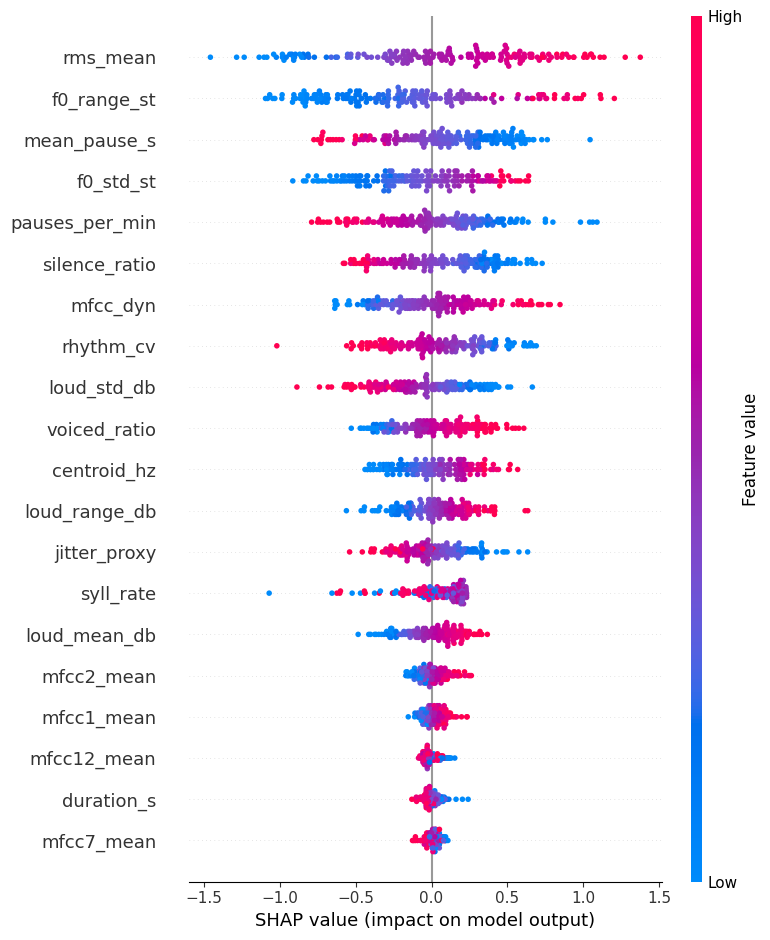

/tmp/ipykernel_1372/876885169.py:8: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(sv, Xs, plot_type="bar", show=False); plt.tight_layout()


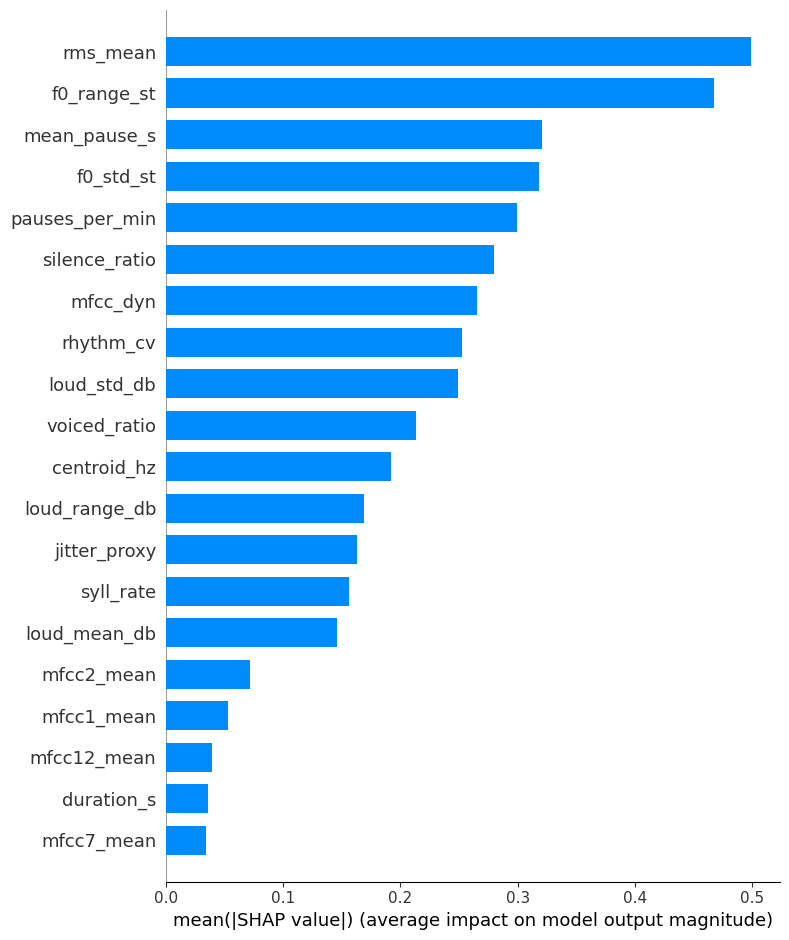

In [ ]:
import shap, matplotlib.pyplot as plt
Xs = X_te.fillna(med)
explainer = shap.Explainer(final.predict, bg)
sv = explainer(Xs)

shap.summary_plot(sv, Xs, show=False); plt.tight_layout()
plt.savefig(f"{BASE}/shap_summary.png", dpi=200, bbox_inches="tight"); plt.show()
shap.summary_plot(sv, Xs, plot_type="bar", show=False); plt.tight_layout()
plt.savefig(f"{BASE}/shap_importance.png", dpi=200, bbox_inches="tight"); plt.show()

In [ ]:
from pathlib import Path

GROUPS = {
 "Pitch variation": ["f0_std_st", "f0_range_st"],
 "Pause patterns":  ["pauses_per_min", "mean_pause_s", "silence_ratio"],
 "Loudness & energy": ["loud_mean_db", "rms_mean", "centroid_hz"],
 "Speaking rhythm": ["syll_rate", "rhythm_cv"],
 "Voice stability": ["jitter_proxy", "loud_std_db", "voiced_ratio"],
 "Expressiveness":  ["loud_range_db"],
 "Voice quality (MFCC)": ["mfcc_dyn"] + [f"mfcc{i}_mean" for i in range(1, 14)],
}
TIPS = {
 "Pitch variation": "Vary your pitch more. Raise and lower your voice to stress key words.",
 "Pause patterns": "Reduce long or frequent pauses. Plan your next sentence while finishing the current one.",
 "Loudness & energy": "Speak louder and with more energy. Project your voice as if talking to the back of a room.",
 "Speaking rhythm": "Keep a steadier pace. Avoid rushing or dragging, and practise with a timer.",
 "Voice stability": "Steady your voice. Breathe slowly before you start and keep your volume consistent.",
 "Expressiveness": "Add more emphasis and emotion. Use louder and softer moments to highlight important points.",
 "Voice quality (MFCC)": "Speak more clearly. Open your mouth and articulate each word.",
}

pack = joblib.load(f"{BASE}/confidence_model.joblib")
model, COLS, med, bg = pack["model"], pack["columns"], pack["median"], pack["background"]
expl = shap.Explainer(model.predict, bg)

def predict_confidence(audio_path):
    """audio_path must be a file preprocessed the same way as the training audio."""
    r = extract(Path(audio_path))
    if "error" in r: raise RuntimeError(r["error"])
    x = pd.DataFrame([r])[COLS].fillna(med)
    score = float(np.clip(model.predict(x)[0], 0, 10))
    sv = expl(x).values[0]
    impact = {g: float(sum(sv[COLS.index(c)] for c in cs if c in COLS)) for g, cs in GROUPS.items()}
    weak = sorted(impact.items(), key=lambda kv: kv[1])[:3]
    return {"confidence_score": round(score, 1),
            "level": "Low" if score < 4 else "Medium" if score < 7 else "High",
            "feedback": [TIPS[g] for g, v in weak if v < 0],
            "factor_impact": {g: round(v, 2) for g, v in impact.items()}}

print(predict_confidence("/content/work/processed_confidence/1000.wav"))

NameError: name 'extract' is not defined

In [ ]:
!pip install -q librosa
import numpy as np, pandas as pd, librosa
from pathlib import Path

SR, HOP = 16000, 320

def extract(path):
    try:
        y, sr = librosa.load(path, sr=SR, mono=True)
        y = y[:SR*90]; dur = len(y)/sr
        rms = librosa.feature.rms(y=y, frame_length=640, hop_length=HOP)[0]
        db = librosa.amplitude_to_db(rms, ref=1.0, top_db=None)
        iv = librosa.effects.split(y, top_db=30, frame_length=640, hop_length=HOP)
        speech = sum(e-s for s, e in iv)/sr
        gaps = [(iv[i+1][0]-iv[i][1])/sr for i in range(len(iv)-1)]
        pauses = [g for g in gaps if g >= 0.25]
        mask = np.zeros(len(rms), bool)
        for s, e in iv: mask[s//HOP: e//HOP+1] = True
        spdb = db[mask] if mask.sum() > 5 else db
        sprms = rms[mask] if mask.sum() > 5 else rms
        f0, _, _ = librosa.pyin(y, fmin=65, fmax=400, sr=sr, frame_length=1024, hop_length=HOP)
        ok = ~np.isnan(f0)
        f0_std = f0_rng = jit = np.nan
        if ok.sum() > 10:
            st = 12*np.log2(f0[ok]/np.median(f0[ok]))
            f0_std = st.std(); f0_rng = np.percentile(st, 95)-np.percentile(st, 5)
            idx = np.where(ok)[0]; d = np.abs(np.diff(st))[np.diff(idx) == 1]
            jit = d.mean() if len(d) else np.nan
        on = librosa.onset.onset_detect(y=y, sr=sr, hop_length=HOP, units="time")
        ioi = np.diff(on); ioi = ioi[ioi < 1.0]
        cv = ioi.std()/ioi.mean() if len(ioi) > 5 else np.nan
        cent = librosa.feature.spectral_centroid(y=y, sr=sr, n_fft=640, hop_length=HOP)[0]
        mf = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=13, n_fft=640, hop_length=HOP, n_mels=40)
        row = {"file": Path(path).stem, "duration_s": round(dur, 2),
               "f0_std_st": f0_std, "f0_range_st": f0_rng, "jitter_proxy": jit, "voiced_ratio": ok.mean(),
               "loud_mean_db": spdb.mean(), "loud_std_db": spdb.std(),
               "loud_range_db": np.percentile(spdb, 95)-np.percentile(spdb, 5),
               "rms_mean": sprms.mean(), "centroid_hz": cent[:len(mask)][mask[:len(cent)]].mean() if mask.sum() > 5 else cent.mean(),
               "pauses_per_min": len(pauses)/dur*60, "mean_pause_s": np.mean(pauses) if pauses else 0.0,
               "silence_ratio": 1-speech/dur, "syll_rate": len(on)/speech if speech > 0 else np.nan,
               "rhythm_cv": cv, "mfcc_dyn": float(np.mean(mf[1:].std(axis=1)))}
        for i in range(13): row[f"mfcc{i+1}_mean"] = mf[i].mean()
        return row
    except Exception as e:
        return {"file": Path(path).stem, "error": str(e)}

In [ ]:
from pathlib import Path

GROUPS = {
 "Pitch variation": ["f0_std_st", "f0_range_st"],
 "Pause patterns":  ["pauses_per_min", "mean_pause_s", "silence_ratio"],
 "Loudness & energy": ["loud_mean_db", "rms_mean", "centroid_hz"],
 "Speaking rhythm": ["syll_rate", "rhythm_cv"],
 "Voice stability": ["jitter_proxy", "loud_std_db", "voiced_ratio"],
 "Expressiveness":  ["loud_range_db"],
 "Voice quality (MFCC)": ["mfcc_dyn"] + [f"mfcc{i}_mean" for i in range(1, 14)],
}
TIPS = {
 "Pitch variation": "Vary your pitch more. Raise and lower your voice to stress key words.",
 "Pause patterns": "Reduce long or frequent pauses. Plan your next sentence while finishing the current one.",
 "Loudness & energy": "Speak louder and with more energy. Project your voice as if talking to the back of a room.",
 "Speaking rhythm": "Keep a steadier pace. Avoid rushing or dragging, and practise with a timer.",
 "Voice stability": "Steady your voice. Breathe slowly before you start and keep your volume consistent.",
 "Expressiveness": "Add more emphasis and emotion. Use louder and softer moments to highlight important points.",
 "Voice quality (MFCC)": "Speak more clearly. Open your mouth and articulate each word.",
}

pack = joblib.load(f"{BASE}/confidence_model.joblib")
model, COLS, med, bg = pack["model"], pack["columns"], pack["median"], pack["background"]
expl = shap.Explainer(model.predict, bg)

def predict_confidence(audio_path):
    """audio_path must be a file preprocessed the same way as the training audio."""
    r = extract(Path(audio_path))
    if "error" in r: raise RuntimeError(r["error"])
    x = pd.DataFrame([r])[COLS].fillna(med)
    score = float(np.clip(model.predict(x)[0], 0, 10))
    sv = expl(x).values[0]
    impact = {g: float(sum(sv[COLS.index(c)] for c in cs if c in COLS)) for g, cs in GROUPS.items()}
    weak = sorted(impact.items(), key=lambda kv: kv[1])[:3]
    return {"confidence_score": round(score, 1),
            "level": "Low" if score < 4 else "Medium" if score < 7 else "High",
            "feedback": [TIPS[g] for g, v in weak if v < 0],
            "factor_impact": {g: round(v, 2) for g, v in impact.items()}}

print(predict_confidence("/content/work/processed_confidence/1000.wav"))

{'confidence_score': 6.9, 'level': 'Medium', 'feedback': ['Steady your voice. Breathe slowly before you start and keep your volume consistent.', 'Keep a steadier pace. Avoid rushing or dragging, and practise with a timer.'], 'factor_impact': {'Pitch variation': 1.3, 'Pause patterns': 0.22, 'Loudness & energy': 0.03, 'Speaking rhythm': -0.07, 'Voice stability': -0.25, 'Expressiveness': 0.13, 'Voice quality (MFCC)': 0.07}}


In [ ]:
print(predict_confidence("/content/work/processed_confidence/1000.wav"))

{'confidence_score': 6.9, 'level': 'Medium', 'feedback': ['Steady your voice. Breathe slowly before you start and keep your volume consistent.', 'Keep a steadier pace. Avoid rushing or dragging, and practise with a timer.'], 'factor_impact': {'Pitch variation': 1.3, 'Pause patterns': 0.2, 'Loudness & energy': 0.03, 'Speaking rhythm': -0.06, 'Voice stability': -0.25, 'Expressiveness': 0.13, 'Voice quality (MFCC)': 0.09}}


In [ ]:
print(ds.loc[ds.file == "1000", "confidence_score"].values)

[7.]


In [ ]:
import json
n = sum(1 for l in open("/content/drive/MyDrive/confidence_project/simple_ratings.jsonl") if l.strip())
print(n, "of 1146 rated")

10 of 1146 rated


In [ ]:
import random
all_files = sorted(AUDIO_DIR.glob("*.wav"))
subset = random.Random(0).sample(all_files, 300)   # fixed sample, same on every rerun
todo = [p for p in subset if p.stem not in done]

NameError: name 'AUDIO_DIR' is not defined

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
import os
if not os.path.exists("/content/work/processed_confidence"):
    !mkdir -p /content/work
    !cp /content/drive/MyDrive/confidence_project/processed_confidence.zip /content/work/
    !cd /content/work && unzip -q -o processed_confidence.zip
print(len(os.listdir("/content/work/processed_confidence")), "audio files")

Mounted at /content/drive
1149 audio files


In [ ]:
!pip install -q google-genai
import json, time, threading, random
import pandas as pd
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor
from google import genai
from google.genai import types
from google.colab import userdata

client = genai.Client(api_key=userdata.get("GEMINI_KEY"))
MODEL = "gemini-3.8-flash"
AUDIO_DIR = Path("/content/work/processed_confidence")
OUT = Path("/content/drive/MyDrive/confidence_project/simple_ratings.jsonl")

PROMPT = """You are a speech communication professor. Listen to this recording and rate the
speaker's CONFIDENCE from 0 to 10 based on vocal delivery only (pauses, hesitation, voice
steadiness, loudness, pitch variation, pace). Ignore content, accent, language, background
noise and other people's voices.
0-2 very nervous, 3-4 unsure, 5-6 average, 7-8 steady and assured, 9-10 very confident.
Use the full range. Return ONLY JSON: {"confidence_score": <number>}"""

SCHEMA = types.Schema(type="OBJECT",
    properties={"confidence_score": types.Schema(type="NUMBER")},
    required=["confidence_score"])

MIN_GAP = 13                      # free tier = 5 requests/minute
_last = [0.0]
gate = threading.Lock()

def wait_turn():
    with gate:
        d = MIN_GAP - (time.time() - _last[0])
        if d > 0:
            time.sleep(d)
        _last[0] = time.time()

def rate(path):
    audio = types.Part.from_bytes(data=path.read_bytes(), mime_type="audio/wav")
    for attempt in range(8):
        wait_turn()
        try:
            r = client.models.generate_content(
                model=MODEL, contents=[PROMPT, audio],
                config=types.GenerateContentConfig(
                    temperature=0, response_mime_type="application/json",
                    response_schema=SCHEMA))
            s = float(json.loads(r.text)["confidence_score"])
            return {"file": path.stem, "confidence_score": round(min(10, max(0, s)), 1)}
        except Exception as e:
            msg = str(e)
            print(path.stem, "error:", msg[:100])
            if "429" in msg:
                time.sleep(60)
            elif "503" in msg:
                time.sleep(20)
            else:
                time.sleep(5)
    return None

# files already rated are skipped
done = set()
if OUT.exists():
    done = {json.loads(l)["file"] for l in OUT.open() if l.strip()}

# fixed random subset of 300 files (same sample on every rerun)
N = 300
all_files = sorted(AUDIO_DIR.glob("*.wav"))
subset = random.Random(0).sample(all_files, N)
todo = [p for p in subset if p.stem not in done]
print("Already done:", len(done), "| To do:", len(todo))

lock = threading.Lock()
def work(p):
    r = rate(p)
    if r:
        with lock, OUT.open("a") as f:
            f.write(json.dumps(r) + "\n")
        print("rated", r)

with ThreadPoolExecutor(1) as ex:
    list(ex.map(work, todo))

if OUT.exists() and OUT.stat().st_size > 0:
    df = pd.read_json(OUT, lines=True, dtype={"file": str})
    df.to_excel("/content/drive/MyDrive/confidence_project/confidence_scores.xlsx", index=False)
    print(len(df), "files rated")
else:
    print("No ratings saved yet. Check the errors above.")

Already done: 10 | To do: 295
rated {'file': '677', 'confidence_score': 3.5}
rated {'file': '742', 'confidence_score': 4.5}
rated {'file': '1072', 'confidence_score': 3.0}
rated {'file': '444', 'confidence_score': 3.8}
rated {'file': '91', 'confidence_score': 3.8}
rated {'file': '863', 'confidence_score': 3.5}
rated {'file': '713', 'confidence_score': 3.5}
526 error: 503 UNAVAILABLE. {'error': {'code': 503, 'message': 'This model is currently experiencing high deman
526 error: 503 UNAVAILABLE. {'error': {'code': 503, 'message': 'This model is currently experiencing high deman
526 error: 429 RESOURCE_EXHAUSTED. {'error': {'code': 429, 'message': 'You exceeded your current quota, please 
526 error: 429 RESOURCE_EXHAUSTED. {'error': {'code': 429, 'message': 'You exceeded your current quota, please 
526 error: 429 RESOURCE_EXHAUSTED. {'error': {'code': 429, 'message': 'You exceeded your current quota, please 
526 error: 429 RESOURCE_EXHAUSTED. {'error': {'code': 429, 'message': 'You exceed

In [ ]:
from google import genai
from google.genai import types
from google.colab import userdata
c = genai.Client(api_key=userdata.get("GEMINI_KEY"))
try:
    c.models.generate_content(model="gemini-3.8-flash", contents="hi")
except Exception as e:
    print(e)

429 RESOURCE_EXHAUSTED. {'error': {'code': 429, 'message': 'You exceeded your current quota, please check your plan and billing details. For more information on this error, head to: https://ai.google.dev/gemini-api/docs/rate-limits. To monitor your current usage, head to: https://ai.dev/rate-limit. \n* Quota exceeded for metric: generativelanguage.googleapis.com/generate_content_free_tier_requests, limit: 20, model: gemini-3.8-flash\nPlease retry in 18h12m47.826981447s.', 'status': 'RESOURCE_EXHAUSTED', 'details': [{'@type': 'type.googleapis.com/google.rpc.Help', 'links': [{'description': 'Learn more about Gemini API quotas', 'url': 'https://ai.google.dev/gemini-api/docs/rate-limits'}]}, {'@type': 'type.googleapis.com/google.rpc.QuotaFailure', 'violations': [{'quotaMetric': 'generativelanguage.googleapis.com/generate_content_free_tier_requests', 'quotaId': 'GenerateRequestsPerDayPerProjectPerModel-FreeTier', 'quotaDimensions': {'location': 'global', 'model': 'gemini-3.8-flash'}, 'quota

In [ ]:
from google import genai
from google.colab import userdata
c = genai.Client(api_key=userdata.get("GEMINI_KEY"))
for m in c.models.list():
    n = m.name.replace("models/", "")
    if "flash" in n:
        try:
            c.models.generate_content(model=n, contents="hi")
            print("OK        ", n)
        except Exception as e:
            s = str(e)
            print("BLOCKED   " if "429" in s else "ERROR     ", n, "|", s[:60])

ERROR      gemini-2.5-flash | 404 NOT_FOUND. {'error': {'code': 404, 'message': 'This mode
ERROR      gemini-2.5-flash-preview-tts | 400 INVALID_ARGUMENT. {'error': {'code': 400, 'message': 'Th
BLOCKED    gemini-flash-latest | 429 RESOURCE_EXHAUSTED. {'error': {'code': 429, 'message': '
OK         gemini-flash-lite-latest
ERROR      gemini-2.5-flash-lite | 404 NOT_FOUND. {'error': {'code': 404, 'message': 'This mode
BLOCKED    gemini-2.5-flash-image | 429 RESOURCE_EXHAUSTED. {'error': {'code': 429, 'message': '
OK         gemini-3-flash-preview
OK         gemini-3.1-flash-lite-preview
OK         gemini-3.1-flash-lite
BLOCKED    gemini-3.1-flash-image-preview | 429 RESOURCE_EXHAUSTED. {'error': {'code': 429, 'message': '
BLOCKED    gemini-3.1-flash-image | 429 RESOURCE_EXHAUSTED. {'error': {'code': 429, 'message': '
BLOCKED    gemini-3.1-flash-lite-image | 429 RESOURCE_EXHAUSTED. {'error': {'code': 429, 'message': '
OK         gemini-3.5-flash
OK         gemini-3.5-flash-lite
BLOCKED   

In [ ]:
import json
from pathlib import Path
from google import genai
from google.genai import types
from google.colab import userdata

c = genai.Client(api_key=userdata.get("GEMINI_KEY"))
M = "gemini-3.1-flash-lite"
p = Path("/content/work/processed_confidence/1002.wav")   # earlier Gemini 3.8 gave this 2.5
try:
    r = c.models.generate_content(
        model=M,
        contents=[PROMPT, types.Part.from_bytes(data=p.read_bytes(), mime_type="audio/wav")],
        config=types.GenerateContentConfig(temperature=0, response_mime_type="application/json", response_schema=SCHEMA))
    print(M, "->", r.text)
except Exception as e:
    print(str(e)[:600])

name 'PROMPT' is not defined


In [ ]:
import json
from pathlib import Path
from google import genai
from google.genai import types
from google.colab import userdata

c = genai.Client(api_key=userdata.get("GEMINI_KEY"))
M = "gemini-3.1-flash-lite"
p = Path("/content/work/processed_confidence/1002.wav")   # Gemini 3.8 gave this file 2.5

PROMPT = """You are a speech communication professor. Listen to this recording and rate the
speaker's CONFIDENCE from 0 to 10 based on vocal delivery only (pauses, hesitation, voice
steadiness, loudness, pitch variation, pace). Ignore content, accent, language, background
noise and other people's voices.
0-2 very nervous, 3-4 unsure, 5-6 average, 7-8 steady and assured, 9-10 very confident.
Use the full range. Return ONLY JSON: {"confidence_score": <number>}"""

SCHEMA = types.Schema(type="OBJECT",
    properties={"confidence_score": types.Schema(type="NUMBER")},
    required=["confidence_score"])

try:
    r = c.models.generate_content(
        model=M,
        contents=[PROMPT, types.Part.from_bytes(data=p.read_bytes(), mime_type="audio/wav")],
        config=types.GenerateContentConfig(temperature=0, response_mime_type="application/json", response_schema=SCHEMA))
    print(M, "->", r.text)
except Exception as e:
    print(str(e)[:600])

[Errno 2] No such file or directory: '/content/work/processed_confidence/1002.wav'


In [ ]:
from google.colab import drive
drive.mount('/content/drive')
import os
if not os.path.exists("/content/work/processed_confidence"):
    !mkdir -p /content/work
    !cp /content/drive/MyDrive/confidence_project/processed_confidence.zip /content/work/
    !cd /content/work && unzip -q -o processed_confidence.zip
print(len(os.listdir("/content/work/processed_confidence")), "audio files")

Mounted at /content/drive
1149 audio files


In [ ]:
from pathlib import Path
files = list(Path("/content/work/processed_confidence").glob("*.wav"))
print(len(files), "wav files")
import os
print([f for f in os.listdir("/content/work/processed_confidence") if not f.endswith(".wav")][:10])

1146 wav files
['preprocessing_duplicates.csv', 'preprocessing_report.csv', 'preprocessing_errors.csv']


In [ ]:
import json
from pathlib import Path
from google import genai
from google.genai import types
from google.colab import userdata

c = genai.Client(api_key=userdata.get("GEMINI_KEY"))
M = "gemini-3.1-flash-lite"
p = Path("/content/work/processed_confidence/1002.wav")   # Gemini 3.8 gave this file 2.5

PROMPT = """You are a speech communication professor. Listen to this recording and rate the
speaker's CONFIDENCE from 0 to 10 based on vocal delivery only (pauses, hesitation, voice
steadiness, loudness, pitch variation, pace). Ignore content, accent, language, background
noise and other people's voices.
0-2 very nervous, 3-4 unsure, 5-6 average, 7-8 steady and assured, 9-10 very confident.
Use the full range. Return ONLY JSON: {"confidence_score": <number>}"""

SCHEMA = types.Schema(type="OBJECT",
    properties={"confidence_score": types.Schema(type="NUMBER")},
    required=["confidence_score"])

try:
    r = c.models.generate_content(
        model=M,
        contents=[PROMPT, types.Part.from_bytes(data=p.read_bytes(), mime_type="audio/wav")],
        config=types.GenerateContentConfig(temperature=0, response_mime_type="application/json", response_schema=SCHEMA))
    print(M, "->", r.text)
except Exception as e:
    print(str(e)[:600])

gemini-3.1-flash-lite -> {"confidence_score": 3}


In [ ]:
!pip install -q google-genai
import json, time, threading, random
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor
from google import genai
from google.genai import types
from google.colab import userdata

client = genai.Client(api_key=userdata.get("GEMINI_KEY"))
MODEL = "gemini-3.1-flash-lite"
AUDIO_DIR = Path("/content/work/processed_confidence")
OUT = Path("/content/drive/MyDrive/confidence_project/simple_ratings_lite.jsonl")
N = 100                           # target number of files; raise later if quota allows

PROMPT = """You are a speech communication professor. Listen to this recording and rate the
speaker's CONFIDENCE from 0 to 10 based on vocal delivery only (pauses, hesitation, voice
steadiness, loudness, pitch variation, pace). Ignore content, accent, language, background
noise and other people's voices.
0-2 very nervous, 3-4 unsure, 5-6 average, 7-8 steady and assured, 9-10 very confident.
Use the full range. Return ONLY JSON: {"confidence_score": <number>}"""

SCHEMA = types.Schema(type="OBJECT",
    properties={"confidence_score": types.Schema(type="NUMBER")},
    required=["confidence_score"])

MIN_GAP = 13
_last = [0.0]
gate = threading.Lock()
lock = threading.Lock()
stop = threading.Event()

def wait_turn():
    with gate:
        d = MIN_GAP - (time.time() - _last[0])
        if d > 0:
            time.sleep(d)
        _last[0] = time.time()

def rate(path):
    audio = types.Part.from_bytes(data=path.read_bytes(), mime_type="audio/wav")
    for attempt in range(8):
        if stop.is_set():
            return None
        wait_turn()
        try:
            r = client.models.generate_content(
                model=MODEL, contents=[PROMPT, audio],
                config=types.GenerateContentConfig(
                    temperature=0, response_mime_type="application/json",
                    response_schema=SCHEMA))
            s = float(json.loads(r.text)["confidence_score"])
            return {"file": path.stem, "confidence_score": round(min(10, max(0, s)), 1)}
        except Exception as e:
            msg = str(e)
            print(path.stem, "error:", msg[:100])
            if "429" in msg:
                if "PerDay" in msg:
                    print("DAILY QUOTA REACHED. Stopping. Rerun later.")
                    stop.set()
                    return None
                time.sleep(60)
            elif "503" in msg:
                time.sleep(20)
            else:
                time.sleep(5)
    return None

def work(p):
    if stop.is_set():
        return
    r = rate(p)
    if r:
        with lock, OUT.open("a") as f:
            f.write(json.dumps(r) + "\n")
        print("rated", r)

done = set()
if OUT.exists():
    done = {json.loads(l)["file"] for l in OUT.open() if l.strip()}

all_files = sorted(AUDIO_DIR.glob("*.wav"))
subset = random.Random(0).sample(all_files, N)     # fixed sample, same on every rerun
todo = [p for p in subset if p.stem not in done]
print("Model:", MODEL, "| Already done:", len(done), "| To do:", len(todo))

with ThreadPoolExecutor(1) as ex:
    list(ex.map(work, todo))

n = sum(1 for l in OUT.open() if l.strip()) if OUT.exists() else 0
print(n, "of", N, "rated")

Model: gemini-3.1-flash-lite | Already done: 0 | To do: 100
rated {'file': '677', 'confidence_score': 4.0}
rated {'file': '742', 'confidence_score': 5.0}
rated {'file': '1072', 'confidence_score': 3.0}
rated {'file': '444', 'confidence_score': 4.0}
91 error: 503 UNAVAILABLE. {'error': {'code': 503, 'message': 'This model is currently experiencing high deman
91 error: 503 UNAVAILABLE. {'error': {'code': 503, 'message': 'This model is currently experiencing high deman
rated {'file': '91', 'confidence_score': 3.0}
rated {'file': '863', 'confidence_score': 4.0}
rated {'file': '713', 'confidence_score': 3.0}
rated {'file': '526', 'confidence_score': 3.0}
rated {'file': '846', 'confidence_score': 3.0}
rated {'file': '627', 'confidence_score': 4.0}
rated {'file': '37', 'confidence_score': 3.0}
rated {'file': '898', 'confidence_score': 3.0}
rated {'file': '223', 'confidence_score': 3.0}
rated {'file': '487', 'confidence_score': 4.0}
rated {'file': '224', 'confidence_score': 2.0}
141 error: 503

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Gemini vs dataset label          n=100  Spearman=0.389  Pearson=0.463  MAE=2.45
Gemini vs model (all 100)        n=100  Spearman=0.387  Pearson=0.463  MAE=2.44
Gemini vs model (test files)     n= 16  Spearman=0.127  Pearson=0.236  MAE=3.04

Gemini score counts:
 gemini
2     8
3    53
4    28
5     9
6     2

Means -> gemini: 3.44 | label: 5.66 | model: 5.65


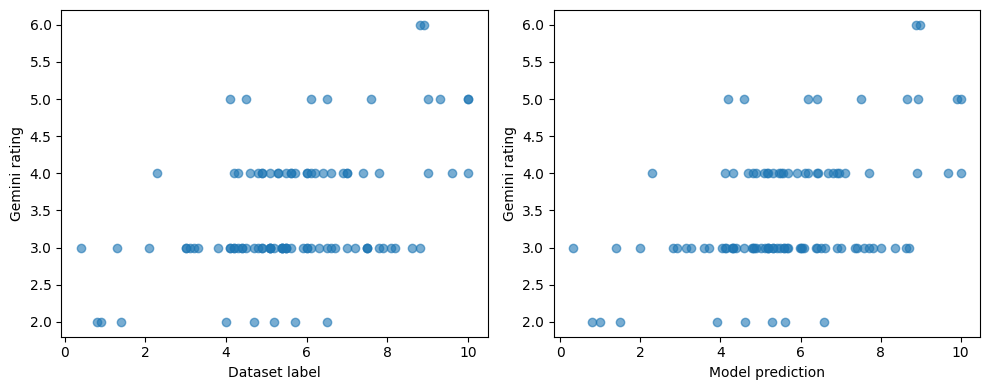

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
import pandas as pd, numpy as np, joblib
from scipy.stats import spearmanr, pearsonr
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error
import matplotlib.pyplot as plt

BASE = "/content/drive/MyDrive/confidence_project"
ds = pd.read_csv(f"{BASE}/confidence_dataset.csv", dtype={"file": str})
art = joblib.load(f"{BASE}/confidence_model.joblib")
model, COLS = art["model"], art["columns"]

g = pd.read_json(f"{BASE}/simple_ratings_lite.jsonl", lines=True, dtype={"file": str}).rename(columns={"confidence_score": "gemini"})
d = ds.merge(g, on="file")
d["model_pred"] = np.clip(model.predict(d[COLS]), 0, 10)

# mark which of these files were in the held-out test split (same split as training)
X = ds.drop(columns=["file", "confidence_score"])
_, X_tmp, _, _ = train_test_split(X, ds.confidence_score, test_size=0.30, random_state=42)
_, X_te, _, _ = train_test_split(X_tmp, ds.loc[X_tmp.index, "confidence_score"], test_size=0.50, random_state=42)
d["is_test"] = d.index.isin(X_te.index) if False else d["file"].isin(ds.loc[X_te.index, "file"])

def report(name, a, b):
    print(f"{name:32s} n={len(a):3d}  Spearman={spearmanr(a,b)[0]:.3f}  Pearson={pearsonr(a,b)[0]:.3f}  MAE={mean_absolute_error(a,b):.2f}")

report("Gemini vs dataset label", d.gemini, d.confidence_score)
report("Gemini vs model (all 100)", d.gemini, d.model_pred)
t = d[d.is_test]
if len(t) > 5:
    report("Gemini vs model (test files)", t.gemini, t.model_pred)

print("\nGemini score counts:\n", d.gemini.value_counts().sort_index().to_string())
print("\nMeans -> gemini:", d.gemini.mean().round(2), "| label:", d.confidence_score.mean().round(2), "| model:", d.model_pred.mean().round(2))

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].scatter(d.confidence_score, d.gemini, alpha=.6); ax[0].set_xlabel("Dataset label"); ax[0].set_ylabel("Gemini rating")
ax[1].scatter(d.model_pred, d.gemini, alpha=.6); ax[1].set_xlabel("Model prediction"); ax[1].set_ylabel("Gemini rating")
plt.tight_layout(); plt.savefig(f"{BASE}/gemini_validation.png", dpi=200, bbox_inches="tight"); plt.show()

In [ ]:
d["gemini_group"] = d.gemini.clip(2, 5).astype(int)   # merge the rare 6s into 5
print(d.groupby("gemini_group")[["confidence_score", "model_pred"]].agg(["mean", "count"]).round(2))

             confidence_score       model_pred      
                         mean count       mean count
gemini_group                                        
2                        3.65     8       3.66     8
3                        5.32    53       5.32    53
4                        6.08    28       6.07    28
5                        7.71    11       7.66    11


In [ ]:
tbl = d.groupby("gemini_group")[["confidence_score", "model_pred"]].agg(["mean", "count"]).round(2)
tbl.to_csv(f"{BASE}/gemini_group_table.csv")

In [ ]:
sample = (d.assign(bin=pd.qcut(d.confidence_score, 3, labels=["low","mid","high"]))
            .groupby("bin", group_keys=False).apply(lambda x: x.sample(10, random_state=1)))
sample = sample.sample(frac=1, random_state=2)
sample[["file"]].assign(my_rating="").to_csv(f"{BASE}/human_check_sheet.csv", index=False)
print(sample[["file"]].head())

   file
54   55
31  319
80  863
90  934
55  551


/tmp/ipykernel_1073/2306392436.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby("bin", group_keys=False).apply(lambda x: x.sample(10, random_state=1)))
/tmp/ipykernel_1073/2306392436.py:2: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .groupby("bin", group_keys=False).apply(lambda x: x.sample(10, random_state=1)))


In [ ]:
from google.colab import drive
drive.mount('/content/drive')
import os, pandas as pd
from IPython.display import Audio, display, clear_output

BASE = "/content/drive/MyDrive/confidence_project"
AUDIO = "/content/work/processed_confidence"
if not os.path.exists(AUDIO):
    !mkdir -p /content/work
    !cp {BASE}/processed_confidence.zip /content/work/
    !cd /content/work && unzip -q -o processed_confidence.zip

SHEET = f"{BASE}/human_check_sheet.csv"
h = pd.read_csv(SHEET, dtype={"file": str})
h["my_rating"] = pd.to_numeric(h["my_rating"], errors="coerce")

for i, row in h.iterrows():
    if pd.notna(row.my_rating):
        continue
    clear_output(wait=True)
    print(f"File {i+1} of {len(h)}  |  rated so far: {h.my_rating.notna().sum()}")
    display(Audio(f"{AUDIO}/{row.file}.wav", autoplay=False))
    ans = input("Confidence 0-10 (vocal delivery only), or 'q' to stop: ").strip()
    if ans.lower() == "q":
        break
    try:
        h.loc[i, "my_rating"] = max(0, min(10, float(ans)))
        h.to_csv(SHEET, index=False)
    except ValueError:
        print("Not a number, skipping. Rerun the cell to come back to it.")
print("Done. Rated:", h.my_rating.notna().sum(), "of", len(h))

File 1 of 30  |  rated so far: 0


KeyboardInterrupt: Interrupted by user

In [ ]:
import os, pandas as pd, librosa, numpy as np
from IPython.display import Audio, display, clear_output

BASE = "/content/drive/MyDrive/confidence_project"
AUDIO = "/content/work/processed_confidence"
SHEET = f"{BASE}/human_check_sheet.csv"
h = pd.read_csv(SHEET, dtype={"file": str})
h["my_rating"] = pd.to_numeric(h["my_rating"], errors="coerce")

for i, row in h.iterrows():
    if pd.notna(row.my_rating):
        continue
    clear_output(wait=True)
    print(f"File {i+1} of {len(h)}  |  rated so far: {h.my_rating.notna().sum()}")
    y, sr = librosa.load(f"{AUDIO}/{row.file}.wav", sr=None, mono=True)
    y = np.clip(y, -1, 1)
    display(Audio(y, rate=sr, normalize=False))
    ans = input("Confidence 0-10 (vocal delivery only), or 'q' to stop: ").strip()
    if ans.lower() == "q":
        break
    try:
        h.loc[i, "my_rating"] = max(0, min(10, float(ans)))
        h.to_csv(SHEET, index=False)
    except ValueError:
        print("Not a number, skipping. Rerun the cell to come back to it.")
print("Done. Rated:", h.my_rating.notna().sum(), "of", len(h))

File 1 of 30  |  rated so far: 0


KeyboardInterrupt: Interrupted by user

In [ ]:
import zipfile
from google.colab import files
h = pd.read_csv(SHEET, dtype={"file": str})
with zipfile.ZipFile("/content/human_check_audio.zip", "w") as z:
    for f in h.file:
        z.write(f"{AUDIO}/{f}.wav", arcname=f"{f}.wav")
files.download("/content/human_check_audio.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import zipfile, pandas as pd
from google.colab import files
BASE = "/content/drive/MyDrive/confidence_project"
AUDIO = "/content/work/processed_confidence"
h = pd.read_csv(f"{BASE}/human_check_sheet.csv", dtype={"file": str})
with zipfile.ZipFile("/content/human_check_audio.zip", "w") as z:
    for f in h.file:
        z.write(f"{AUDIO}/{f}.wav", arcname=f"{f}.wav")
files.download("/content/human_check_audio.zip")
print(list(h.file))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

['55', '319', '863', '934', '551', '949', '837', '581', '875', '501', '87', '627', '701', '963', '969', '713', '625', '793', '689', '134', '788', '557', '91', '363', '118', '1125', '864', '877', '798', '783']


Mounted at /content/drive
Ratings found: 30 of 30
Human vs dataset label     n=30  Spearman=0.558  Pearson=0.591  MAE=1.62
Human vs model prediction  n=30  Spearman=0.565  Pearson=0.595  MAE=1.62
Human vs Gemini            n=30  Spearman=0.704  Pearson=0.678  MAE=2.87
Mean -> human: 6.17 | label: 5.64 | model: 5.61


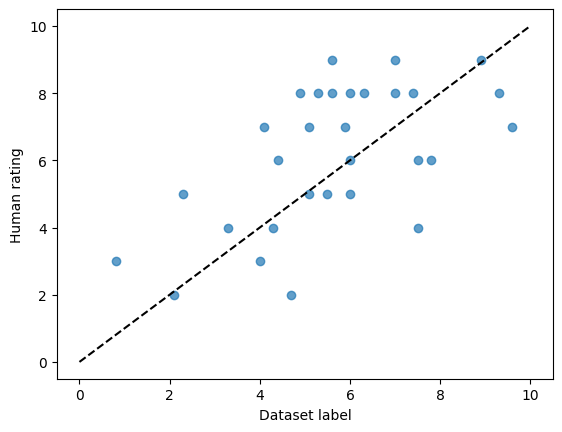

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
import pandas as pd, numpy as np, joblib
from scipy.stats import spearmanr, pearsonr
from sklearn.metrics import mean_absolute_error

BASE = "/content/drive/MyDrive/confidence_project"
h = pd.read_csv(f"{BASE}/human_check_sheet.csv", dtype={"file": str})
h["my_rating"] = pd.to_numeric(h["my_rating"], errors="coerce")
print("Ratings found:", h.my_rating.notna().sum(), "of", len(h))
assert h.my_rating.notna().sum() >= 20, "Ratings not saved in this file. See the note below."

ds = pd.read_csv(f"{BASE}/confidence_dataset.csv", dtype={"file": str})
art = joblib.load(f"{BASE}/confidence_model.joblib")
ds["model_pred"] = np.clip(art["model"].predict(ds[art["columns"]]), 0, 10)
g = pd.read_json(f"{BASE}/simple_ratings_lite.jsonl", lines=True, dtype={"file": str}).rename(columns={"confidence_score": "gemini"})

m = h.merge(ds[["file", "confidence_score", "model_pred"]], on="file").merge(g, on="file", how="left")

for col, name in [("confidence_score", "dataset label"), ("model_pred", "model prediction"), ("gemini", "Gemini")]:
    x = m.dropna(subset=["my_rating", col])
    print(f"Human vs {name:17s} n={len(x):2d}  Spearman={spearmanr(x.my_rating, x[col])[0]:.3f}  "
          f"Pearson={pearsonr(x.my_rating, x[col])[0]:.3f}  MAE={mean_absolute_error(x.my_rating, x[col]):.2f}")
print("Mean -> human:", m.my_rating.mean().round(2), "| label:", m.confidence_score.mean().round(2),
      "| model:", m.model_pred.mean().round(2))

import matplotlib.pyplot as plt
plt.scatter(m.confidence_score, m.my_rating, alpha=.7); plt.plot([0,10],[0,10],"k--")
plt.xlabel("Dataset label"); plt.ylabel("Human rating")
plt.savefig(f"{BASE}/human_vs_label.png", dpi=200, bbox_inches="tight"); plt.show()

In [ ]:
import numpy as np
rng = np.random.default_rng(0)
def boot_ci(a, b, n=2000):
    r = [spearmanr(a[i], b[i])[0] for i in (rng.integers(0, len(a), len(a)) for _ in range(n))]
    return np.percentile(r, [2.5, 97.5]).round(2)
x = m.dropna(subset=["my_rating", "confidence_score"])
print("Human vs label 95% CI:", boot_ci(x.my_rating.values, x.confidence_score.values))
x = m.dropna(subset=["my_rating", "gemini"])
print("Human vs Gemini 95% CI:", boot_ci(x.my_rating.values, x.gemini.values))
m.to_csv(f"{BASE}/validation_30_files.csv", index=False)

Human vs label 95% CI: [0.24 0.77]
Human vs Gemini 95% CI: [0.46 0.86]


In [ ]:
import inspect
print(inspect.getsource(predict_confidence))

NameError: name 'predict_confidence' is not defined

In [ ]:
from pathlib import Path

GROUPS = {
 "Pitch variation": ["f0_std_st", "f0_range_st"],
 "Pause patterns":  ["pauses_per_min", "mean_pause_s", "silence_ratio"],
 "Loudness & energy": ["loud_mean_db", "rms_mean", "centroid_hz"],
 "Speaking rhythm": ["syll_rate", "rhythm_cv"],
 "Voice stability": ["jitter_proxy", "loud_std_db", "voiced_ratio"],
 "Expressiveness":  ["loud_range_db"],
 "Voice quality (MFCC)": ["mfcc_dyn"] + [f"mfcc{i}_mean" for i in range(1, 14)],
}
TIPS = {
 "Pitch variation": "Vary your pitch more. Raise and lower your voice to stress key words.",
 "Pause patterns": "Reduce long or frequent pauses. Plan your next sentence while finishing the current one.",
 "Loudness & energy": "Speak louder and with more energy. Project your voice as if talking to the back of a room.",
 "Speaking rhythm": "Keep a steadier pace. Avoid rushing or dragging, and practise with a timer.",
 "Voice stability": "Steady your voice. Breathe slowly before you start and keep your volume consistent.",
 "Expressiveness": "Add more emphasis and emotion. Use louder and softer moments to highlight important points.",
 "Voice quality (MFCC)": "Speak more clearly. Open your mouth and articulate each word.",
}

pack = joblib.load(f"{BASE}/confidence_model.joblib")
model, COLS, med, bg = pack["model"], pack["columns"], pack["median"], pack["background"]
expl = shap.Explainer(model.predict, bg)

def predict_confidence(audio_path):
    """audio_path must be a file preprocessed the same way as the training audio."""
    r = extract(Path(audio_path))
    if "error" in r: raise RuntimeError(r["error"])
    x = pd.DataFrame([r])[COLS].fillna(med)
    score = float(np.clip(model.predict(x)[0], 0, 10))
    sv = expl(x).values[0]
    impact = {g: float(sum(sv[COLS.index(c)] for c in cs if c in COLS)) for g, cs in GROUPS.items()}
    weak = sorted(impact.items(), key=lambda kv: kv[1])[:3]
    return {"confidence_score": round(score, 1),
            "level": "Low" if score < 4 else "Medium" if score < 7 else "High",
            "feedback": [TIPS[g] for g, v in weak if v < 0],
            "factor_impact": {g: round(v, 2) for g, v in impact.items()}}

print(predict_confidence("/content/work/processed_confidence/1000.wav"))

NameError: name 'shap' is not defined

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
!pip install -q shap xgboost librosa

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import numpy as np, pandas as pd, joblib, shap
from pathlib import Path

BASE = "/content/drive/MyDrive/confidence_project"

GROUPS = {
 "Pitch variation": ["f0_std_st", "f0_range_st"],
 "Pause patterns":  ["pauses_per_min", "mean_pause_s", "silence_ratio"],
 "Loudness & energy": ["loud_mean_db", "rms_mean", "centroid_hz"],
 "Speaking rhythm": ["syll_rate", "rhythm_cv"],
 "Voice stability": ["jitter_proxy", "loud_std_db", "voiced_ratio"],
 "Expressiveness":  ["loud_range_db"],
 "Voice quality (MFCC)": ["mfcc_dyn"] + [f"mfcc{i}_mean" for i in range(1, 14)],
}
TIPS = {
 "Pitch variation": "Vary your pitch more. Raise and lower your voice to stress key words.",
 "Pause patterns": "Reduce long or frequent pauses. Plan your next sentence while finishing the current one.",
 "Loudness & energy": "Speak louder and with more energy. Project your voice as if talking to the back of a room.",
 "Speaking rhythm": "Keep a steadier pace. Avoid rushing or dragging, and practise with a timer.",
 "Voice stability": "Steady your voice. Breathe slowly before you start and keep your volume consistent.",
 "Expressiveness": "Add more emphasis and emotion. Use louder and softer moments to highlight important points.",
 "Voice quality (MFCC)": "Speak more clearly. Open your mouth and articulate each word.",
}

pack = joblib.load(f"{BASE}/confidence_model.joblib")
model, COLS, med, bg = pack["model"], pack["columns"], pack["median"], pack["background"]
expl = shap.Explainer(model.predict, bg)

def predict_confidence(audio_path):
    """audio_path must be preprocessed the same way as the training audio."""
    r = extract(Path(audio_path))
    if "error" in r: raise RuntimeError(r["error"])
    x = pd.DataFrame([r])[COLS].fillna(med)
    score = float(np.clip(model.predict(x)[0], 0, 10))
    sv = expl(x).values[0]
    impact = {g: float(sum(sv[COLS.index(c)] for c in cs if c in COLS)) for g, cs in GROUPS.items()}
    weak = sorted(impact.items(), key=lambda kv: kv[1])[:3]
    fb = [TIPS[g] for g, v in weak if v < -0.15]
    return {"confidence_score": round(score, 1),
            "level": "Low" if score < 4 else "Medium" if score < 7 else "High",
            "feedback": fb or ["Good delivery. No major weaknesses found."],
            "factor_impact": {g: round(v, 2) for g, v in impact.items()}}

print(predict_confidence("/content/work/processed_confidence/1000.wav"))

NameError: name 'extract' is not defined

In [ ]:
import librosa

SR, HOP = 16000, 320

def extract(path):
    try:
        y, sr = librosa.load(path, sr=SR, mono=True)
        y = y[:SR*90]; dur = len(y)/sr
        rms = librosa.feature.rms(y=y, frame_length=640, hop_length=HOP)[0]
        db = librosa.amplitude_to_db(rms, ref=1.0, top_db=None)
        iv = librosa.effects.split(y, top_db=30, frame_length=640, hop_length=HOP)
        speech = sum(e-s for s, e in iv)/sr
        gaps = [(iv[i+1][0]-iv[i][1])/sr for i in range(len(iv)-1)]
        pauses = [g for g in gaps if g >= 0.25]
        mask = np.zeros(len(rms), bool)
        for s, e in iv: mask[s//HOP: e//HOP+1] = True
        spdb = db[mask] if mask.sum() > 5 else db
        sprms = rms[mask] if mask.sum() > 5 else rms
        f0, _, _ = librosa.pyin(y, fmin=65, fmax=400, sr=sr, frame_length=1024, hop_length=HOP)
        ok = ~np.isnan(f0)
        f0_std = f0_rng = jit = np.nan
        if ok.sum() > 10:
            st = 12*np.log2(f0[ok]/np.median(f0[ok]))
            f0_std = st.std(); f0_rng = np.percentile(st, 95)-np.percentile(st, 5)
            idx = np.where(ok)[0]; d = np.abs(np.diff(st))[np.diff(idx) == 1]
            jit = d.mean() if len(d) else np.nan
        on = librosa.onset.onset_detect(y=y, sr=sr, hop_length=HOP, units="time")
        ioi = np.diff(on); ioi = ioi[ioi < 1.0]
        cv = ioi.std()/ioi.mean() if len(ioi) > 5 else np.nan
        cent = librosa.feature.spectral_centroid(y=y, sr=sr, n_fft=640, hop_length=HOP)[0]
        mf = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=13, n_fft=640, hop_length=HOP, n_mels=40)
        row = {"file": Path(path).stem, "duration_s": round(dur, 2),
               "f0_std_st": f0_std, "f0_range_st": f0_rng, "jitter_proxy": jit, "voiced_ratio": ok.mean(),
               "loud_mean_db": spdb.mean(), "loud_std_db": spdb.std(),
               "loud_range_db": np.percentile(spdb, 95)-np.percentile(spdb, 5),
               "rms_mean": sprms.mean(), "centroid_hz": cent[:len(mask)][mask[:len(cent)]].mean() if mask.sum() > 5 else cent.mean(),
               "pauses_per_min": len(pauses)/dur*60, "mean_pause_s": np.mean(pauses) if pauses else 0.0,
               "silence_ratio": 1-speech/dur, "syll_rate": len(on)/speech if speech > 0 else np.nan,
               "rhythm_cv": cv, "mfcc_dyn": float(np.mean(mf[1:].std(axis=1)))}
        for i in range(13): row[f"mfcc{i+1}_mean"] = mf[i].mean()
        return row
    except Exception as e:
        return {"file": Path(path).stem, "error": str(e)}

In [ ]:
print(predict_confidence("/content/work/processed_confidence/1000.wav"))

/tmp/ipykernel_996/2771274271.py:7: UserWarning: PySoundFile failed. Trying audioread instead.
  y, sr = librosa.load(path, sr=SR, mono=True)
/usr/local/lib/python3.13/dist-packages/librosa/core/audio.py:184: FutureWarning: librosa.core.audio.__audioread_load
	Deprecated as of librosa version 0.10.0.
	It will be removed in librosa version 1.0.
  y, sr_native = __audioread_load(path, offset, duration, dtype)


RuntimeError: [Errno 2] No such file or directory: '/content/work/processed_confidence/1000.wav'

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
!mkdir -p /content/work
!cp /content/drive/MyDrive/confidence_project/processed_confidence.zip /content/work/
!cd /content/work && unzip -q -o processed_confidence.zip
!ls /content/work/processed_confidence/*.wav | wc -l

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
1146


In [ ]:
print(predict_confidence("/content/work/processed_confidence/1000.wav"))

{'confidence_score': 6.9, 'level': 'Medium', 'feedback': ['Steady your voice. Breathe slowly before you start and keep your volume consistent.'], 'factor_impact': {'Pitch variation': 1.31, 'Pause patterns': 0.21, 'Loudness & energy': 0.03, 'Speaking rhythm': -0.06, 'Voice stability': -0.25, 'Expressiveness': 0.13, 'Voice quality (MFCC)': 0.08}}


In [ ]:
!ls -lh /content/drive/MyDrive/confidence_project | head -20
!ls /content/work | head

total 1.3G
-rw------- 1 root root 151K Oct 13 06:32 all_feature_scores.xlsx
-rw------- 1 root root 2.5K Oct 13 07:27 all_scores.jsonl
-rw------- 1 root root 435K Oct 13 17:21 confidence_dataset.csv
-rw------- 1 root root 224K Oct 13 17:30 confidence_model.joblib
-rw------- 1 root root  106 Oct 12 08:36 confidence_scores.csv
-rw------- 1 root root 4.9K Oct 12 17:12 confidence_scores.xlsx
-rw------- 1 root root 433K Oct 13 06:31 features.csv
-rw------- 1 root root   48 Oct 13 17:30 final_test_metrics.csv
-rw------- 1 root root  167 Oct 14 06:31 gemini_group_table.csv
-rw------- 1 root root  70K Oct 14 06:28 gemini_validation.png
-rw------- 1 root root  224 Oct 14 08:06 human_check_sheet.csv
-rw------- 1 root root  48K Oct 14 08:18 human_vs_label.png
-rw------- 1 root root  186 Oct 13 17:30 model_comparison_validation.csv
-rw------- 1 root root 7.7K Oct 12 05:19 preprocess_fluency_audio.py
-rw------- 1 root root 1.2G Oct 12 07:19 processed_confidence.zip
-rw------- 1 root root 116M Oct 12

In [ ]:
import pandas as pd
print(pd.read_csv("/content/drive/MyDrive/confidence_project/model_comparison_validation.csv"))
print(pd.read_csv("/content/drive/MyDrive/confidence_project/final_test_metrics.csv"))

          model    MAE   RMSE     R2  Spearman
0           SVR  0.261  0.372  0.965     0.986
1       XGBoost  0.290  0.375  0.964     0.981
2     NeuralNet  0.408  0.561  0.920     0.956
3  RandomForest  0.452  0.579  0.915     0.956
4         Ridge  0.572  0.724  0.867     0.928
  Unnamed: 0      0
0        MAE  0.252
1       RMSE  0.334
2         R2  0.977
3   Spearman  0.988


In [ ]:
GROUPS = {
 "Pitch variation": ["f0_std_st", "f0_range_st"],
 "Pause patterns":  ["pauses_per_min", "mean_pause_s", "silence_ratio"],
 "Loudness & energy": ["loud_mean_db", "rms_mean", "centroid_hz"],
 "Speaking rhythm": ["syll_rate", "rhythm_cv"],
 "Voice stability": ["jitter_proxy", "loud_std_db", "voiced_ratio"],
 "Expressiveness":  ["loud_range_db"],
 "Voice quality (MFCC)": ["mfcc_dyn"] + [f"mfcc{i}_mean" for i in range(1, 14)],
}

In [ ]:
import pandas as pd
from scipy.stats import spearmanr
BASE = "/content/drive/MyDrive/confidence_project"
ds = pd.read_csv(f"{BASE}/confidence_dataset.csv", dtype={"file": str})
g = pd.read_json(f"{BASE}/simple_ratings_lite.jsonl", lines=True, dtype={"file": str}).rename(columns={"confidence_score": "gemini"})
m = ds.merge(g, on="file")
print(len(m), "files | Spearman:", round(spearmanr(m.gemini, m.confidence_score)[0], 3))

100 files | Spearman: 0.389


In [ ]:
!pip install -q gradio
import gradio as gr, subprocess, tempfile

FILTERS = "highpass=f=60:p=2,lowpass=f=7600:p=2,afftdn=nr=12:nf=-45:tn=1:ad=0.5:gs=6,alimiter=limit=0.891251:level=0:latency=1"

def analyse(audio_path):
    if audio_path is None:
        return "Upload or record audio first.", "", {}
    tmp = tempfile.mktemp(suffix=".wav")
    subprocess.run(["ffmpeg", "-hide_banner", "-loglevel", "error", "-y", "-i", audio_path,
                    "-vn", "-ac", "1", "-ar", "16000", "-af", FILTERS, tmp], check=True)
    r = predict_confidence(tmp)
    if "error" in r:
        return "Error: " + r["error"], "", {}
    return (f"{r['confidence_score']} / 10  ({r['level']})",
            "\n".join("• " + f for f in r["feedback"]), r["factor_impact"])

gr.Interface(analyse, gr.Audio(type="filepath", sources=["upload", "microphone"]),
             [gr.Textbox(label="Confidence score"), gr.Textbox(label="Feedback"),
              gr.JSON(label="Factor impact")],
             title="Speaking Confidence Detection").launch(share=True, debug=True)

Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://d1b45534397bdc9459.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


Created dataset file at: .gradio/flagged/dataset1.csv


In [ ]:
!pip install -q gradio gtts
import gradio as gr, subprocess, tempfile, os
import numpy as np, pandas as pd, librosa
import matplotlib.pyplot as plt
from scipy.stats import percentileofscore
from gtts import gTTS

BASE = "/content/drive/MyDrive/confidence_project"
REF = pd.read_csv(f"{BASE}/confidence_dataset.csv")
FILTERS = "highpass=f=60:p=2,lowpass=f=7600:p=2,afftdn=nr=12:nf=-45:tn=1:ad=0.5:gs=6,alimiter=limit=0.891251:level=0:latency=1"

# compute features once per recording (pitch tracking is slow)
_cache = {}
if not hasattr(extract, "_cached"):
    _orig_extract = extract
    def extract(path, _o=_orig_extract):
        k = str(path)
        if k not in _cache:
            _cache[k] = _o(path)
        return _cache[k]
    extract._cached = True

# ---- 0-10 feature scores, relative to your 1146 training recordings (5 = average) ----
def pct(col, v):
    if v is None or pd.isna(v): return 5.0
    return percentileofscore(REF[col].dropna().values, v, kind="mean") / 10
def hi(c, r):  return pct(c, r.get(c))
def lo(c, r):  return 10 - pct(c, r.get(c))
def mid(c, r): return (1 - abs(pct(c, r.get(c)) / 10 - 0.5) * 2) * 10

def feature_scores(r):
    m = lambda *v: float(np.mean(v))
    return {
     "Pitch variation":  m(hi("f0_std_st", r), hi("f0_range_st", r)),
     "Pause patterns":   m(lo("pauses_per_min", r), lo("silence_ratio", r), lo("mean_pause_s", r)),
     "Loudness":         hi("loud_mean_db", r),
     "Speaking rhythm":  m(mid("syll_rate", r), lo("rhythm_cv", r)),
     "Vocal energy":     m(hi("rms_mean", r), hi("centroid_hz", r)),
     "Voice stability":  m(lo("jitter_proxy", r), lo("loud_std_db", r), hi("voiced_ratio", r)),
     "Expressiveness":   m(hi("f0_range_st", r), hi("loud_range_db", r)),
     "Voice quality (MFCC)": hi("mfcc_dyn", r),
    }

# ---- graphs ----
def gauge(score):
    fig, ax = plt.subplots(figsize=(6, 1.8))
    for a, b, c in [(0, 4, "#e74c3c"), (4, 7, "#f1c40f"), (7, 10, "#2ecc71")]:
        ax.barh(0, b - a, left=a, color=c, height=0.5)
    ax.plot([score, score], [-0.45, 0.45], color="black", lw=4)
    ax.text(score, 0.6, f"{score:.1f}", ha="center", fontsize=14, fontweight="bold")
    ax.set_xlim(0, 10); ax.set_ylim(-0.6, 1.1); ax.set_yticks([]); ax.set_xticks([0, 4, 7, 10])
    ax.set_title("Confidence score (Low | Medium | High)")
    for s in ("top", "right", "left"): ax.spines[s].set_visible(False)
    fig.tight_layout(); return fig

def radar(fs):
    labels, vals = list(fs), list(fs.values())
    ang = np.linspace(0, 2 * np.pi, len(labels), endpoint=False).tolist()
    vals += vals[:1]; ang += ang[:1]
    fig = plt.figure(figsize=(5.5, 5.5)); ax = plt.subplot(111, polar=True)
    ax.plot(ang, [5] * len(ang), "--", color="gray", lw=1, label="Dataset average")
    ax.plot(ang, vals, color="#2c7be5", lw=2); ax.fill(ang, vals, color="#2c7be5", alpha=0.25)
    ax.set_xticks(ang[:-1]); ax.set_xticklabels(labels, fontsize=8); ax.set_ylim(0, 10)
    ax.set_title("Feature scores (0-10)", y=1.1)
    ax.legend(loc="lower right", bbox_to_anchor=(1.25, -0.05), fontsize=8)
    fig.tight_layout(); return fig

def impact_bar(imp):
    items = sorted(imp.items(), key=lambda kv: kv[1])
    fig, ax = plt.subplots(figsize=(6, 3.6))
    ax.barh([k for k, _ in items], [v for _, v in items],
            color=["#e74c3c" if v < 0 else "#2ecc71" for _, v in items])
    ax.axvline(0, color="black", lw=1)
    ax.set_xlabel("Effect on your score (points, vs. an average speaker)")
    ax.set_title("What raised or lowered your score"); fig.tight_layout(); return fig

def waveform(path):
    y, sr = librosa.load(path, sr=16000, mono=True); y = y[:sr * 90]
    iv = librosa.effects.split(y, top_db=30, frame_length=640, hop_length=320)
    fig, ax = plt.subplots(figsize=(8, 2.8))
    ax.plot(np.arange(len(y)) / sr, y, lw=0.4, color="#2c7be5")
    n = 0
    for i in range(len(iv) - 1):
        g0, g1 = iv[i][1] / sr, iv[i + 1][0] / sr
        if g1 - g0 >= 0.25:
            ax.axvspan(g0, g1, color="#e74c3c", alpha=0.3); n += 1
    ax.set_xlabel("Time (s)"); ax.set_title(f"Waveform, pauses highlighted ({n} pauses of 0.25 s or more)")
    fig.tight_layout(); return fig

# ---- spoken feedback ----
def spoken_text(res):
    imp = res["factor_impact"]; best = max(imp, key=imp.get)
    t = f"Your confidence score is {res['confidence_score']} out of 10, which is a {res['level']} level. "
    if imp[best] > 0.15:
        t += f"Your strongest area is {best.lower()}. "
    t += "Here is my feedback. " + " ".join(res["feedback"])
    return t.replace(" (MFCC)", "")

NONE7 = (None,) * 5

def analyse(audio_path):
    plt.close("all")
    if audio_path is None:
        return ("Upload or record audio first.", "") + NONE7
    tmp = tempfile.mktemp(suffix=".wav")
    try:
        subprocess.run(["ffmpeg", "-hide_banner", "-loglevel", "error", "-y", "-i", audio_path,
                        "-vn", "-ac", "1", "-ar", "16000", "-af", FILTERS, tmp], check=True)
        res = predict_confidence(tmp)
        if "error" in res:
            return ("Error: " + res["error"], "") + NONE7
        fs = feature_scores(extract(tmp))
        mp3 = None
        try:
            mp3 = tempfile.mktemp(suffix=".mp3")
            gTTS(spoken_text(res), lang="en").save(mp3)
        except Exception as e:
            print("Voice feedback failed:", e); mp3 = None
        return (f"{res['confidence_score']} / 10  ({res['level']})",
                "\n".join("• " + f for f in res["feedback"]),
                gauge(res["confidence_score"]), radar(fs),
                impact_bar(res["factor_impact"]), waveform(tmp), mp3)
    except Exception as e:
        return (f"Error: {e}", "") + NONE7
    finally:
        _cache.pop(tmp, None)
        if os.path.exists(tmp): os.remove(tmp)

with gr.Blocks(title="Speaking Confidence Detection") as demo:
    gr.Markdown("# Speaking Confidence Detection\nUpload or record up to 1 minute of English speech, then click **Analyse**.")
    with gr.Row():
        with gr.Column(scale=1):
            inp = gr.Audio(sources=["upload", "microphone"], type="filepath", label="Your speech")
            btn = gr.Button("Analyse", variant="primary")
            score = gr.Textbox(label="Confidence score")
            fb = gr.Textbox(label="Feedback", lines=5)
            voice = gr.Audio(label="Spoken feedback", autoplay=True, interactive=False)
        with gr.Column(scale=2):
            g = gr.Plot(label="Score")
            with gr.Row():
                r = gr.Plot(label="Feature scores")
                i = gr.Plot(label="Impact")
            w = gr.Plot(label="Waveform")
    btn.click(analyse, inp, [score, fb, g, r, i, w, voice])

demo.launch(share=True, debug=True)

In [ ]:
!pip install -q gradio gtts
import gradio as gr, subprocess, tempfile, os
import numpy as np, pandas as pd, librosa
import matplotlib.pyplot as plt
from scipy.stats import percentileofscore
from gtts import gTTS

BASE = "/content/drive/MyDrive/confidence_project"
REF = pd.read_csv(f"{BASE}/confidence_dataset.csv")
FILTERS = "highpass=f=60:p=2,lowpass=f=7600:p=2,afftdn=nr=12:nf=-45:tn=1:ad=0.5:gs=6,alimiter=limit=0.891251:level=0:latency=1"

# compute features once per recording (pitch tracking is slow)
_cache = {}
if not hasattr(extract, "_cached"):
    _orig_extract = extract
    def extract(path, _o=_orig_extract):
        k = str(path)
        if k not in _cache:
            _cache[k] = _o(path)
        return _cache[k]
    extract._cached = True

# ---- 0-10 feature scores, relative to your 1146 training recordings (5 = average) ----
def pct(col, v):
    if v is None or pd.isna(v): return 5.0
    return percentileofscore(REF[col].dropna().values, v, kind="mean") / 10
def hi(c, r):  return pct(c, r.get(c))
def lo(c, r):  return 10 - pct(c, r.get(c))
def mid(c, r): return (1 - abs(pct(c, r.get(c)) / 10 - 0.5) * 2) * 10

def feature_scores(r):
    m = lambda *v: float(np.mean(v))
    return {
     "Pitch variation":  m(hi("f0_std_st", r), hi("f0_range_st", r)),
     "Pause patterns":   m(lo("pauses_per_min", r), lo("silence_ratio", r), lo("mean_pause_s", r)),
     "Loudness":         hi("loud_mean_db", r),
     "Speaking rhythm":  m(mid("syll_rate", r), lo("rhythm_cv", r)),
     "Vocal energy":     m(hi("rms_mean", r), hi("centroid_hz", r)),
     "Voice stability":  m(lo("jitter_proxy", r), lo("loud_std_db", r), hi("voiced_ratio", r)),
     "Expressiveness":   m(hi("f0_range_st", r), hi("loud_range_db", r)),
     "Voice quality (MFCC)": hi("mfcc_dyn", r),
    }

# ---- graphs ----
def gauge(score):
    fig, ax = plt.subplots(figsize=(6, 1.8))
    for a, b, c in [(0, 4, "#e74c3c"), (4, 7, "#f1c40f"), (7, 10, "#2ecc71")]:
        ax.barh(0, b - a, left=a, color=c, height=0.5)
    ax.plot([score, score], [-0.45, 0.45], color="black", lw=4)
    ax.text(score, 0.6, f"{score:.1f}", ha="center", fontsize=14, fontweight="bold")
    ax.set_xlim(0, 10); ax.set_ylim(-0.6, 1.1); ax.set_yticks([]); ax.set_xticks([0, 4, 7, 10])
    ax.set_title("Confidence score (Low | Medium | High)")
    for s in ("top", "right", "left"): ax.spines[s].set_visible(False)
    fig.tight_layout(); return fig

def radar(fs):
    labels, vals = list(fs), list(fs.values())
    ang = np.linspace(0, 2 * np.pi, len(labels), endpoint=False).tolist()
    vals += vals[:1]; ang += ang[:1]
    fig = plt.figure(figsize=(5.5, 5.5)); ax = plt.subplot(111, polar=True)
    ax.plot(ang, [5] * len(ang), "--", color="gray", lw=1, label="Dataset average")
    ax.plot(ang, vals, color="#2c7be5", lw=2); ax.fill(ang, vals, color="#2c7be5", alpha=0.25)
    ax.set_xticks(ang[:-1]); ax.set_xticklabels(labels, fontsize=8); ax.set_ylim(0, 10)
    ax.set_title("Feature scores (0-10)", y=1.1)
    ax.legend(loc="lower right", bbox_to_anchor=(1.25, -0.05), fontsize=8)
    fig.tight_layout(); return fig

def impact_bar(imp):
    items = sorted(imp.items(), key=lambda kv: kv[1])
    fig, ax = plt.subplots(figsize=(6, 3.6))
    ax.barh([k for k, _ in items], [v for _, v in items],
            color=["#e74c3c" if v < 0 else "#2ecc71" for _, v in items])
    ax.axvline(0, color="black", lw=1)
    ax.set_xlabel("Effect on your score (points, vs. an average speaker)")
    ax.set_title("What raised or lowered your score"); fig.tight_layout(); return fig

def waveform(path):
    y, sr = librosa.load(path, sr=16000, mono=True); y = y[:sr * 90]
    iv = librosa.effects.split(y, top_db=30, frame_length=640, hop_length=320)
    fig, ax = plt.subplots(figsize=(8, 2.8))
    ax.plot(np.arange(len(y)) / sr, y, lw=0.4, color="#2c7be5")
    n = 0
    for i in range(len(iv) - 1):
        g0, g1 = iv[i][1] / sr, iv[i + 1][0] / sr
        if g1 - g0 >= 0.25:
            ax.axvspan(g0, g1, color="#e74c3c", alpha=0.3); n += 1
    ax.set_xlabel("Time (s)"); ax.set_title(f"Waveform, pauses highlighted ({n} pauses of 0.25 s or more)")
    fig.tight_layout(); return fig

# ---- spoken feedback ----
def spoken_text(res):
    imp = res["factor_impact"]; best = max(imp, key=imp.get)
    t = f"Your confidence score is {res['confidence_score']} out of 10, which is a {res['level']} level. "
    if imp[best] > 0.15:
        t += f"Your strongest area is {best.lower()}. "
    t += "Here is my feedback. " + " ".join(res["feedback"])
    return t.replace(" (MFCC)", "")

NONE7 = (None,) * 5

def analyse(audio_path):
    plt.close("all")
    if audio_path is None:
        return ("Upload or record audio first.", "") + NONE7
    tmp = tempfile.mktemp(suffix=".wav")
    try:
        subprocess.run(["ffmpeg", "-hide_banner", "-loglevel", "error", "-y", "-i", audio_path,
                        "-vn", "-ac", "1", "-ar", "16000", "-af", FILTERS, tmp], check=True)
        res = predict_confidence(tmp)
        if "error" in res:
            return ("Error: " + res["error"], "") + NONE7
        fs = feature_scores(extract(tmp))
        mp3 = None
        try:
            mp3 = tempfile.mktemp(suffix=".mp3")
            gTTS(spoken_text(res), lang="en").save(mp3)
        except Exception as e:
            print("Voice feedback failed:", e); mp3 = None
        return (f"{res['confidence_score']} / 10  ({res['level']})",
                "\n".join("• " + f for f in res["feedback"]),
                gauge(res["confidence_score"]), radar(fs),
                impact_bar(res["factor_impact"]), waveform(tmp), mp3)
    except Exception as e:
        return (f"Error: {e}", "") + NONE7
    finally:
        _cache.pop(tmp, None)
        if os.path.exists(tmp): os.remove(tmp)

with gr.Blocks(title="Speaking Confidence Detection") as demo:
    gr.Markdown("# Speaking Confidence Detection\nUpload or record up to 1 minute of English speech, then click **Analyse**.")
    with gr.Row():
        with gr.Column(scale=1):
            inp = gr.Audio(sources=["upload", "microphone"], type="filepath", label="Your speech")
            btn = gr.Button("Analyse", variant="primary")
            score = gr.Textbox(label="Confidence score")
            fb = gr.Textbox(label="Feedback", lines=5)
            voice = gr.Audio(label="Spoken feedback", autoplay=True, interactive=False)
        with gr.Column(scale=2):
            g = gr.Plot(label="Score")
            with gr.Row():
                r = gr.Plot(label="Feature scores")
                i = gr.Plot(label="Impact")
            w = gr.Plot(label="Waveform")
    btn.click(analyse, inp, [score, fb, g, r, i, w, voice])

demo.launch(share=True, debug=True)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 98.2/98.2 kB 2.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 668.2/668.2 kB 10.8 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
diffusers 0.40.0 requires huggingface-hub<2.0,>=1.23.0, but you have huggingface-hub 1.16.1 which is incompatible.
spacy 3.8.16 requires click<9.0.0,>=8.2.1, but you have click 8.1.8 which is incompatible.
wandb 0.28.1 requires click>=8.2.0, but you have click 8.1.8 which is incompatible.
transformers 5.18.0 requires huggingface-hub<3.0,>=1.31.0, but you have huggingface-hub 1.16.1 which is incompatible.


FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/confidence_project/confidence_dataset.csv'

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
!ls /content/drive/MyDrive/confidence_project

Mounted at /content/drive
all_feature_scores.xlsx		 preprocess_fluency_audio.py
all_scores.jsonl		 processed_confidence.zip
confidence_dataset.csv		 raw_audio.zip
confidence_model.joblib		 shap_importance.png
confidence_scores.csv		 shap_summary.png
confidence_scores.xlsx		 simple_ratings.jsonl
features.csv			 simple_ratings_lite.jsonl
final_test_metrics.csv		 test_evaluation.png
gemini_group_table.csv		 train_val_test_charts.png
gemini_validation.png		 train_val_test_results.csv
human_check_sheet.csv		 train_val_test_summary_table.csv
human_vs_label.png		 validation_30_files.csv
model_comparison_validation.csv


In [ ]:
!pip install -q shap librosa
import numpy as np, pandas as pd, joblib, shap, librosa
from pathlib import Path

BASE = "/content/drive/MyDrive/confidence_project"
SR, HOP = 16000, 320

def extract(path):
    try:
        y, sr = librosa.load(path, sr=SR, mono=True)
        y = y[:SR*90]; dur = len(y)/sr
        rms = librosa.feature.rms(y=y, frame_length=640, hop_length=HOP)[0]
        db = librosa.amplitude_to_db(rms, ref=1.0, top_db=None)
        iv = librosa.effects.split(y, top_db=30, frame_length=640, hop_length=HOP)
        speech = sum(e-s for s, e in iv)/sr
        gaps = [(iv[i+1][0]-iv[i][1])/sr for i in range(len(iv)-1)]
        pauses = [g for g in gaps if g >= 0.25]
        mask = np.zeros(len(rms), bool)
        for s, e in iv: mask[s//HOP: e//HOP+1] = True
        spdb = db[mask] if mask.sum() > 5 else db
        sprms = rms[mask] if mask.sum() > 5 else rms
        f0, _, _ = librosa.pyin(y, fmin=65, fmax=400, sr=sr, frame_length=1024, hop_length=HOP)
        ok = ~np.isnan(f0)
        f0_std = f0_rng = jit = np.nan
        if ok.sum() > 10:
            st = 12*np.log2(f0[ok]/np.median(f0[ok]))
            f0_std = st.std(); f0_rng = np.percentile(st, 95)-np.percentile(st, 5)
            idx = np.where(ok)[0]; d = np.abs(np.diff(st))[np.diff(idx) == 1]
            jit = d.mean() if len(d) else np.nan
        on = librosa.onset.onset_detect(y=y, sr=sr, hop_length=HOP, units="time")
        ioi = np.diff(on); ioi = ioi[ioi < 1.0]
        cv = ioi.std()/ioi.mean() if len(ioi) > 5 else np.nan
        cent = librosa.feature.spectral_centroid(y=y, sr=sr, n_fft=640, hop_length=HOP)[0]
        mf = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=13, n_fft=640, hop_length=HOP, n_mels=40)
        row = {"file": Path(path).stem, "duration_s": round(dur, 2),
               "f0_std_st": f0_std, "f0_range_st": f0_rng, "jitter_proxy": jit, "voiced_ratio": ok.mean(),
               "loud_mean_db": spdb.mean(), "loud_std_db": spdb.std(),
               "loud_range_db": np.percentile(spdb, 95)-np.percentile(spdb, 5),
               "rms_mean": sprms.mean(), "centroid_hz": cent[:len(mask)][mask[:len(cent)]].mean() if mask.sum() > 5 else cent.mean(),
               "pauses_per_min": len(pauses)/dur*60, "mean_pause_s": np.mean(pauses) if pauses else 0.0,
               "silence_ratio": 1-speech/dur, "syll_rate": len(on)/speech if speech > 0 else np.nan,
               "rhythm_cv": cv, "mfcc_dyn": float(np.mean(mf[1:].std(axis=1)))}
        for i in range(13): row[f"mfcc{i+1}_mean"] = mf[i].mean()
        return row
    except Exception as e:
        return {"file": Path(path).stem, "error": str(e)}

art = joblib.load(f"{BASE}/confidence_model.joblib")
model, COLS, MED, BG = art["model"], art["columns"], art["median"], art["background"]
explainer = shap.Explainer(model.predict, BG)

GROUPS = {
 "Pitch variation": ["f0_std_st", "f0_range_st"],
 "Pause patterns":  ["pauses_per_min", "mean_pause_s", "silence_ratio"],
 "Loudness & energy": ["loud_mean_db", "rms_mean", "centroid_hz"],
 "Speaking rhythm": ["syll_rate", "rhythm_cv"],
 "Voice stability": ["jitter_proxy", "loud_std_db", "voiced_ratio"],
 "Expressiveness":  ["loud_range_db"],
 "Voice quality (MFCC)": ["mfcc_dyn"] + [f"mfcc{i}_mean" for i in range(1, 14)],
}
TIPS = {
 "Pitch variation": "Vary your pitch more. Raise and lower your voice to stress key words.",
 "Pause patterns": "Reduce long or frequent pauses. Plan your next sentence while finishing the current one.",
 "Loudness & energy": "Speak louder and with more energy. Project your voice as if talking to the back of a room.",
 "Speaking rhythm": "Keep a steadier pace. Avoid rushing or dragging, and practise with a timer.",
 "Voice stability": "Steady your voice. Breathe slowly before you start and keep your volume consistent.",
 "Expressiveness": "Add more emphasis and emotion. Use louder and softer moments to highlight important points.",
 "Voice quality (MFCC)": "Speak more clearly. Open your mouth and articulate each word.",
}
THRESH, LOW, HIGH = -0.15, 4, 7

def predict_confidence(path):
    row = extract(str(path))
    if "error" in row: return {"error": row["error"]}
    x = pd.DataFrame([row]).reindex(columns=COLS).fillna(MED)
    score = float(np.clip(model.predict(x)[0], 0, 10))
    contrib = dict(zip(COLS, explainer(x).values[0]))
    impact = {g: float(sum(contrib[c] for c in cs if c in contrib)) for g, cs in GROUPS.items()}
    weak = sorted([(g, v) for g, v in impact.items() if v < THRESH], key=lambda t: t[1])[:2]
    fb = [TIPS[g] for g, _ in weak] or ["Good delivery. No major weaknesses found."]
    return {"confidence_score": round(score, 1),
            "level": "Low" if score < LOW else "High" if score >= HIGH else "Medium",
            "feedback": fb, "factor_impact": {g: round(v, 2) for g, v in impact.items()}}
print("Model and functions ready")

Model and functions ready


In [ ]:
print(predict_confidence("/content/your_file.wav"))

{'error': "[Errno 2] No such file or directory: '/content/your_file.wav'"}


/tmp/ipykernel_2957/2349515919.py:10: UserWarning: PySoundFile failed. Trying audioread instead.
  y, sr = librosa.load(path, sr=SR, mono=True)
/usr/local/lib/python3.13/dist-packages/librosa/core/audio.py:184: FutureWarning: librosa.core.audio.__audioread_load
	Deprecated as of librosa version 0.10.0.
	It will be removed in librosa version 1.0.
  y, sr_native = __audioread_load(path, offset, duration, dtype)


In [ ]:
!pip install -q gradio gtts
import gradio as gr, subprocess, tempfile, os
import numpy as np, pandas as pd, librosa
import matplotlib.pyplot as plt
from scipy.stats import percentileofscore
from gtts import gTTS

BASE = "/content/drive/MyDrive/confidence_project"
REF = pd.read_csv(f"{BASE}/confidence_dataset.csv")
FILTERS = "highpass=f=60:p=2,lowpass=f=7600:p=2,afftdn=nr=12:nf=-45:tn=1:ad=0.5:gs=6,alimiter=limit=0.891251:level=0:latency=1"

# compute features once per recording (pitch tracking is slow)
_cache = {}
if not hasattr(extract, "_cached"):
    _orig_extract = extract
    def extract(path, _o=_orig_extract):
        k = str(path)
        if k not in _cache:
            _cache[k] = _o(path)
        return _cache[k]
    extract._cached = True

# ---- 0-10 feature scores, relative to your 1146 training recordings (5 = average) ----
def pct(col, v):
    if v is None or pd.isna(v): return 5.0
    return percentileofscore(REF[col].dropna().values, v, kind="mean") / 10
def hi(c, r):  return pct(c, r.get(c))
def lo(c, r):  return 10 - pct(c, r.get(c))
def mid(c, r): return (1 - abs(pct(c, r.get(c)) / 10 - 0.5) * 2) * 10

def feature_scores(r):
    m = lambda *v: float(np.mean(v))
    return {
     "Pitch variation":  m(hi("f0_std_st", r), hi("f0_range_st", r)),
     "Pause patterns":   m(lo("pauses_per_min", r), lo("silence_ratio", r), lo("mean_pause_s", r)),
     "Loudness":         hi("loud_mean_db", r),
     "Speaking rhythm":  m(mid("syll_rate", r), lo("rhythm_cv", r)),
     "Vocal energy":     m(hi("rms_mean", r), hi("centroid_hz", r)),
     "Voice stability":  m(lo("jitter_proxy", r), lo("loud_std_db", r), hi("voiced_ratio", r)),
     "Expressiveness":   m(hi("f0_range_st", r), hi("loud_range_db", r)),
     "Voice quality (MFCC)": hi("mfcc_dyn", r),
    }

# ---- graphs ----
def gauge(score):
    fig, ax = plt.subplots(figsize=(6, 1.8))
    for a, b, c in [(0, 4, "#e74c3c"), (4, 7, "#f1c40f"), (7, 10, "#2ecc71")]:
        ax.barh(0, b - a, left=a, color=c, height=0.5)
    ax.plot([score, score], [-0.45, 0.45], color="black", lw=4)
    ax.text(score, 0.6, f"{score:.1f}", ha="center", fontsize=14, fontweight="bold")
    ax.set_xlim(0, 10); ax.set_ylim(-0.6, 1.1); ax.set_yticks([]); ax.set_xticks([0, 4, 7, 10])
    ax.set_title("Confidence score (Low | Medium | High)")
    for s in ("top", "right", "left"): ax.spines[s].set_visible(False)
    fig.tight_layout(); return fig

def radar(fs):
    labels, vals = list(fs), list(fs.values())
    ang = np.linspace(0, 2 * np.pi, len(labels), endpoint=False).tolist()
    vals += vals[:1]; ang += ang[:1]
    fig = plt.figure(figsize=(5.5, 5.5)); ax = plt.subplot(111, polar=True)
    ax.plot(ang, [5] * len(ang), "--", color="gray", lw=1, label="Dataset average")
    ax.plot(ang, vals, color="#2c7be5", lw=2); ax.fill(ang, vals, color="#2c7be5", alpha=0.25)
    ax.set_xticks(ang[:-1]); ax.set_xticklabels(labels, fontsize=8); ax.set_ylim(0, 10)
    ax.set_title("Feature scores (0-10)", y=1.1)
    ax.legend(loc="lower right", bbox_to_anchor=(1.25, -0.05), fontsize=8)
    fig.tight_layout(); return fig

def impact_bar(imp):
    items = sorted(imp.items(), key=lambda kv: kv[1])
    fig, ax = plt.subplots(figsize=(6, 3.6))
    ax.barh([k for k, _ in items], [v for _, v in items],
            color=["#e74c3c" if v < 0 else "#2ecc71" for _, v in items])
    ax.axvline(0, color="black", lw=1)
    ax.set_xlabel("Effect on your score (points, vs. an average speaker)")
    ax.set_title("What raised or lowered your score"); fig.tight_layout(); return fig

def waveform(path):
    y, sr = librosa.load(path, sr=16000, mono=True); y = y[:sr * 90]
    iv = librosa.effects.split(y, top_db=30, frame_length=640, hop_length=320)
    fig, ax = plt.subplots(figsize=(8, 2.8))
    ax.plot(np.arange(len(y)) / sr, y, lw=0.4, color="#2c7be5")
    n = 0
    for i in range(len(iv) - 1):
        g0, g1 = iv[i][1] / sr, iv[i + 1][0] / sr
        if g1 - g0 >= 0.25:
            ax.axvspan(g0, g1, color="#e74c3c", alpha=0.3); n += 1
    ax.set_xlabel("Time (s)"); ax.set_title(f"Waveform, pauses highlighted ({n} pauses of 0.25 s or more)")
    fig.tight_layout(); return fig

# ---- spoken feedback ----
def spoken_text(res):
    imp = res["factor_impact"]; best = max(imp, key=imp.get)
    t = f"Your confidence score is {res['confidence_score']} out of 10, which is a {res['level']} level. "
    if imp[best] > 0.15:
        t += f"Your strongest area is {best.lower()}. "
    t += "Here is my feedback. " + " ".join(res["feedback"])
    return t.replace(" (MFCC)", "")

NONE7 = (None,) * 5

def analyse(audio_path):
    plt.close("all")
    if audio_path is None:
        return ("Upload or record audio first.", "") + NONE7
    tmp = tempfile.mktemp(suffix=".wav")
    try:
        subprocess.run(["ffmpeg", "-hide_banner", "-loglevel", "error", "-y", "-i", audio_path,
                        "-vn", "-ac", "1", "-ar", "16000", "-af", FILTERS, tmp], check=True)
        res = predict_confidence(tmp)
        if "error" in res:
            return ("Error: " + res["error"], "") + NONE7
        fs = feature_scores(extract(tmp))
        mp3 = None
        try:
            mp3 = tempfile.mktemp(suffix=".mp3")
            gTTS(spoken_text(res), lang="en").save(mp3)
        except Exception as e:
            print("Voice feedback failed:", e); mp3 = None
        return (f"{res['confidence_score']} / 10  ({res['level']})",
                "\n".join("• " + f for f in res["feedback"]),
                gauge(res["confidence_score"]), radar(fs),
                impact_bar(res["factor_impact"]), waveform(tmp), mp3)
    except Exception as e:
        return (f"Error: {e}", "") + NONE7
    finally:
        _cache.pop(tmp, None)
        if os.path.exists(tmp): os.remove(tmp)

with gr.Blocks(title="Speaking Confidence Detection") as demo:
    gr.Markdown("# Speaking Confidence Detection\nUpload or record up to 1 minute of English speech, then click **Analyse**.")
    with gr.Row():
        with gr.Column(scale=1):
            inp = gr.Audio(sources=["upload", "microphone"], type="filepath", label="Your speech")
            btn = gr.Button("Analyse", variant="primary")
            score = gr.Textbox(label="Confidence score")
            fb = gr.Textbox(label="Feedback", lines=5)
            voice = gr.Audio(label="Spoken feedback", autoplay=True, interactive=False)
        with gr.Column(scale=2):
            g = gr.Plot(label="Score")
            with gr.Row():
                r = gr.Plot(label="Feature scores")
                i = gr.Plot(label="Impact")
            w = gr.Plot(label="Waveform")
    btn.click(analyse, inp, [score, fb, g, r, i, w, voice])

demo.launch(share=True, debug=True)

Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://efb57acf2ac621bc65.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:
from google.colab import drive
drive.mount('/content/drive')
!ls /content/drive/MyDrive/confidence_project

Mounted at /content/drive
all_feature_scores.xlsx  human_vs_label.png
all_scores.jsonl	 model_comparison_validation.csv
confidence_dataset.csv	 preprocess_fluency_audio.py
confidence_model.joblib  processed_confidence.zip
confidence_scores.csv	 raw_audio.zip
confidence_scores.xlsx	 shap_importance.png
features.csv		 shap_summary.png
final_test_metrics.csv	 simple_ratings.jsonl
gemini_group_table.csv	 simple_ratings_lite.jsonl
gemini_validation.png	 validation_30_files.csv
human_check_sheet.csv


In [ ]:
from google.colab import drive
drive.mount('/content/drive')
import pandas as pd
BASE = "/content/drive/MyDrive/confidence_project"
print(pd.read_csv(f"{BASE}/model_comparison_validation.csv"))
print(pd.read_csv(f"{BASE}/final_test_metrics.csv"))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
          model    MAE   RMSE     R2  Spearman
0           SVR  0.261  0.372  0.965     0.986
1       XGBoost  0.290  0.375  0.964     0.981
2     NeuralNet  0.408  0.561  0.920     0.956
3  RandomForest  0.452  0.579  0.915     0.956
4         Ridge  0.572  0.724  0.867     0.928
  Unnamed: 0      0
0        MAE  0.252
1       RMSE  0.334
2         R2  0.977
3   Spearman  0.988


Best model: SVR | test rows: 172
MAE      : 0.252 (average error in score points)
RMSE     : 0.334
R2       : 0.977
Spearman : 0.988
Baseline MAE (guess the mean): 1.806
Level accuracy: 91.3 %
Predicted  High  Low  Medium
Actual                      
High         55    0       5
Low           0   31       4
Medium        5    1      71


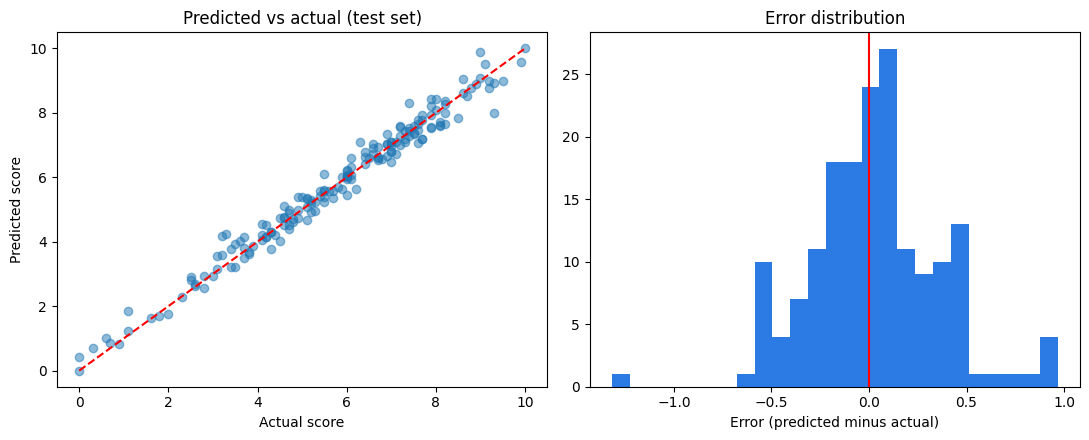

In [ ]:
import numpy as np, joblib, matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from scipy.stats import spearmanr

ds = pd.read_csv(f"{BASE}/confidence_dataset.csv", dtype={"file": str})
art = joblib.load(f"{BASE}/confidence_model.joblib")
model, COLS = art["model"], art["columns"]

X = ds[COLS]; y = ds["confidence_score"]
X_tr, X_tmp, y_tr, y_tmp = train_test_split(X, y, test_size=0.30, random_state=42)
X_val, X_te, y_val, y_te = train_test_split(X_tmp, y_tmp, test_size=0.50, random_state=42)

p = np.clip(model.predict(X_te), 0, 10)
print("Best model:", art["name"], "| test rows:", len(y_te))
print("MAE      :", round(mean_absolute_error(y_te, p), 3), "(average error in score points)")
print("RMSE     :", round(mean_squared_error(y_te, p) ** 0.5, 3))
print("R2       :", round(r2_score(y_te, p), 3))
print("Spearman :", round(spearmanr(y_te, p)[0], 3))

# Baseline: always guess the training average
base = np.full(len(y_te), y_tr.mean())
print("Baseline MAE (guess the mean):", round(mean_absolute_error(y_te, base), 3))

# Low / Medium / High agreement
lvl = lambda s: np.where(s < 4, "Low", np.where(s >= 7, "High", "Medium"))
print("Level accuracy:", round((lvl(y_te.values) == lvl(p)).mean() * 100, 1), "%")
print(pd.crosstab(pd.Series(lvl(y_te.values), name="Actual"), pd.Series(lvl(p), name="Predicted")))

fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
ax[0].scatter(y_te, p, alpha=0.5); ax[0].plot([0, 10], [0, 10], "r--")
ax[0].set_xlabel("Actual score"); ax[0].set_ylabel("Predicted score"); ax[0].set_title("Predicted vs actual (test set)")
ax[1].hist(p - y_te, bins=25, color="#2c7be5"); ax[1].axvline(0, color="r")
ax[1].set_xlabel("Error (predicted minus actual)"); ax[1].set_title("Error distribution")
plt.tight_layout(); plt.savefig(f"{BASE}/test_evaluation.png", dpi=200); plt.show()

Mounted at /content/drive
{'Train': 802, 'Validation': 172, 'Test': 172}
done Ridge
done RandomForest
done SVR
done XGBoost
done NeuralNet

R2
 Split         Train  Validation   Test
Model                                 
NeuralNet     0.985       0.920  0.949
RandomForest  0.987       0.915  0.915
Ridge         0.923       0.867  0.912
SVR           0.998       0.965  0.975
XGBoost       0.995       0.964  0.969

MAE
 Split         Train  Validation   Test
Model                                 
NeuralNet     0.197       0.408  0.383
RandomForest  0.195       0.452  0.488
Ridge         0.480       0.572  0.515
SVR           0.082       0.261  0.265
XGBoost       0.126       0.290  0.299

RMSE
 Split         Train  Validation   Test
Model                                 
NeuralNet     0.272       0.561  0.491
RandomForest  0.257       0.579  0.636
Ridge         0.618       0.724  0.646
SVR           0.095       0.372  0.346
XGBoost       0.160       0.375  0.385

Spearman
 Split        

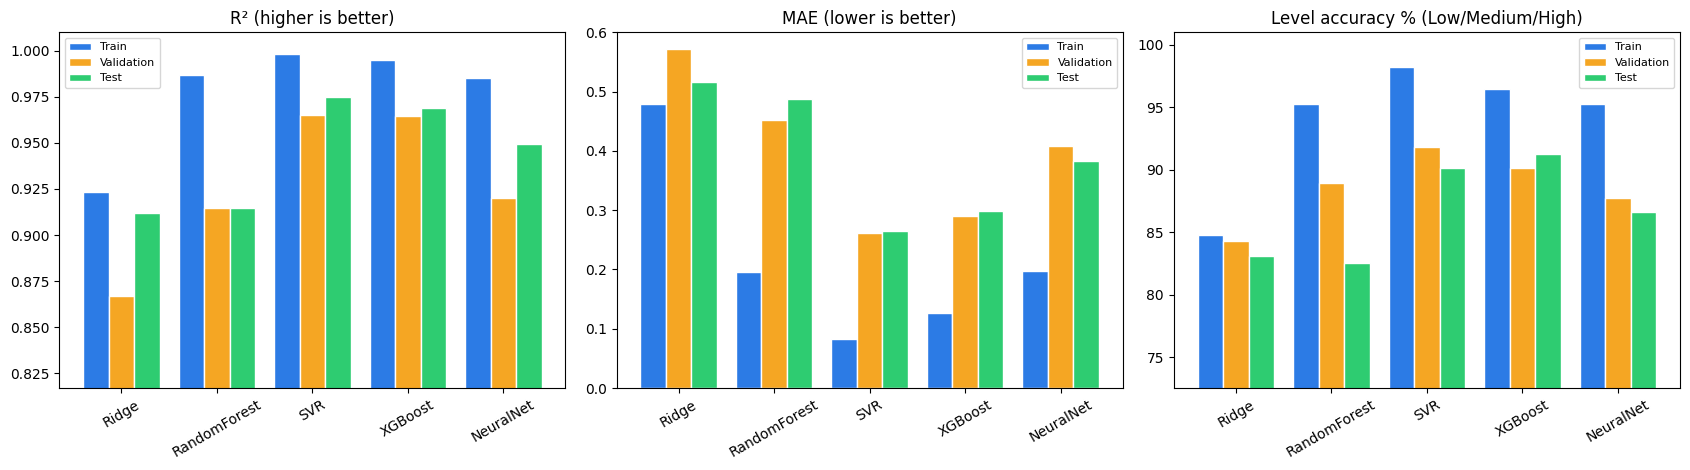


Overfitting check (R² gap, small = good)
 Split          Test  Train  Validation  Train-Val gap
Model                                                
NeuralNet     0.949  0.985       0.920          0.065
RandomForest  0.915  0.987       0.915          0.072
Ridge         0.912  0.923       0.867          0.056
SVR           0.975  0.998       0.965          0.033
XGBoost       0.969  0.995       0.964          0.031


In [ ]:
from google.colab import drive
drive.mount('/content/drive')
!pip install -q xgboost
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.stats import loguniform, randint, uniform, spearmanr
from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR
from sklearn.neural_network import MLPRegressor
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

BASE = "/content/drive/MyDrive/confidence_project"
ds = pd.read_csv(f"{BASE}/confidence_dataset.csv", dtype={"file": str})
X = ds.drop(columns=["file", "confidence_score"]); y = ds["confidence_score"]

X_tr, X_tmp, y_tr, y_tmp = train_test_split(X, y, test_size=0.30, random_state=42)
X_val, X_te, y_val, y_te = train_test_split(X_tmp, y_tmp, test_size=0.50, random_state=42)
SETS = {"Train": (X_tr, y_tr), "Validation": (X_val, y_val), "Test": (X_te, y_te)}
print({k: len(v[0]) for k, v in SETS.items()})

def pipe(m): return Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler()), ("m", m)])
SPACES = {
 "Ridge":        (pipe(Ridge()), {"m__alpha": loguniform(1e-2, 1e3)}),
 "RandomForest": (pipe(RandomForestRegressor(random_state=0, n_jobs=-1)),
                  {"m__n_estimators": randint(100, 500), "m__max_depth": [None, 6, 10, 16], "m__min_samples_leaf": randint(1, 10)}),
 "SVR":          (pipe(SVR()), {"m__C": loguniform(0.1, 100), "m__gamma": loguniform(1e-3, 1e-1), "m__epsilon": uniform(0.05, 0.5)}),
 "XGBoost":      (pipe(XGBRegressor(random_state=0, n_jobs=-1)),
                  {"m__n_estimators": randint(100, 600), "m__max_depth": randint(2, 7),
                   "m__learning_rate": loguniform(0.02, 0.3), "m__subsample": uniform(0.6, 0.4)}),
 "NeuralNet":    (pipe(MLPRegressor(max_iter=1500, early_stopping=True, random_state=0)),
                  {"m__hidden_layer_sizes": [(32,), (64,), (64, 32), (128, 64)],
                   "m__alpha": loguniform(1e-5, 1e-1), "m__learning_rate_init": loguniform(1e-3, 1e-2)}),
}
lvl = lambda s: np.where(np.asarray(s) < 4, 0, np.where(np.asarray(s) >= 7, 2, 1))   # Low / Medium / High

rows = []
for name, (est, space) in SPACES.items():
    best = RandomizedSearchCV(est, space, n_iter=20, cv=5, scoring="neg_mean_absolute_error",
                              random_state=0, n_jobs=-1).fit(X_tr, y_tr).best_estimator_
    for split, (Xs, ys) in SETS.items():
        p = np.clip(best.predict(Xs), 0, 10)
        rows.append({"Model": name, "Split": split,
                     "R2": r2_score(ys, p), "MAE": mean_absolute_error(ys, p),
                     "RMSE": mean_squared_error(ys, p) ** 0.5,
                     "Spearman": spearmanr(ys, p)[0],
                     "Level accuracy (%)": (lvl(ys) == lvl(p)).mean() * 100})
    print("done", name)

R = pd.DataFrame(rows)
R.round(3).to_csv(f"{BASE}/train_val_test_results.csv", index=False)

# ---- TABLES ----
for m in ["R2", "MAE", "RMSE", "Spearman", "Level accuracy (%)"]:
    t = R.pivot(index="Model", columns="Split", values=m)[["Train", "Validation", "Test"]]
    print(f"\n{m}\n", t.round(3))
summary = R.pivot(index="Model", columns="Split", values=["R2", "MAE", "Level accuracy (%)"]).round(3)
summary.to_csv(f"{BASE}/train_val_test_summary_table.csv")

# ---- CHARTS ----
cols = {"Train": "#2c7be5", "Validation": "#f5a623", "Test": "#2ecc71"}
fig, ax = plt.subplots(1, 3, figsize=(17, 4.8))
for a, m, title in zip(ax, ["R2", "MAE", "Level accuracy (%)"],
                       ["R² (higher is better)", "MAE (lower is better)", "Level accuracy % (Low/Medium/High)"]):
    t = R.pivot(index="Model", columns="Split", values=m)[["Train", "Validation", "Test"]].loc[list(SPACES)]
    t.plot(kind="bar", ax=a, color=[cols[c] for c in t.columns], width=0.8, edgecolor="white")
    a.set_title(title); a.set_xlabel(""); a.tick_params(axis="x", rotation=30); a.legend(fontsize=8)
    if m == "R2": a.set_ylim(max(0, t.min().min() - 0.05), 1.01)
    if m.startswith("Level"): a.set_ylim(max(0, t.min().min() - 10), 101)
plt.tight_layout(); plt.savefig(f"{BASE}/train_val_test_charts.png", dpi=200); plt.show()

# Train vs Validation gap (overfitting check)
g = R.pivot(index="Model", columns="Split", values="R2")
g["Train-Val gap"] = g["Train"] - g["Validation"]
print("\nOverfitting check (R² gap, small = good)\n", g.round(3))

In [ ]:
!pip install -q gradio gtts
import gradio as gr, subprocess, tempfile, os
import numpy as np, pandas as pd, librosa
import matplotlib.pyplot as plt
from scipy.stats import percentileofscore
from gtts import gTTS

BASE = "/content/drive/MyDrive/confidence_project"
REF = pd.read_csv(f"{BASE}/confidence_dataset.csv")
FILTERS = "highpass=f=60:p=2,lowpass=f=7600:p=2,afftdn=nr=12:nf=-45:tn=1:ad=0.5:gs=6,alimiter=limit=0.891251:level=0:latency=1"

# compute features once per recording (pitch tracking is slow)
_cache = {}
if not hasattr(extract, "_cached"):
    _orig_extract = extract
    def extract(path, _o=_orig_extract):
        k = str(path)
        if k not in _cache:
            _cache[k] = _o(path)
        return _cache[k]
    extract._cached = True

# ---- 0-10 feature scores, relative to your 1146 training recordings (5 = average) ----
def pct(col, v):
    if v is None or pd.isna(v): return 5.0
    return percentileofscore(REF[col].dropna().values, v, kind="mean") / 10
def hi(c, r):  return pct(c, r.get(c))
def lo(c, r):  return 10 - pct(c, r.get(c))
def mid(c, r): return (1 - abs(pct(c, r.get(c)) / 10 - 0.5) * 2) * 10

def feature_scores(r):
    m = lambda *v: float(np.mean(v))
    return {
     "Pitch variation":  m(hi("f0_std_st", r), hi("f0_range_st", r)),
     "Pause patterns":   m(lo("pauses_per_min", r), lo("silence_ratio", r), lo("mean_pause_s", r)),
     "Loudness":         hi("loud_mean_db", r),
     "Speaking rhythm":  m(mid("syll_rate", r), lo("rhythm_cv", r)),
     "Vocal energy":     m(hi("rms_mean", r), hi("centroid_hz", r)),
     "Voice stability":  m(lo("jitter_proxy", r), lo("loud_std_db", r), hi("voiced_ratio", r)),
     "Expressiveness":   m(hi("f0_range_st", r), hi("loud_range_db", r)),
     "Voice quality (MFCC)": hi("mfcc_dyn", r),
    }

# ---- graphs ----
def gauge(score):
    fig, ax = plt.subplots(figsize=(6, 1.8))
    for a, b, c in [(0, 4, "#e74c3c"), (4, 7, "#f1c40f"), (7, 10, "#2ecc71")]:
        ax.barh(0, b - a, left=a, color=c, height=0.5)
    ax.plot([score, score], [-0.45, 0.45], color="black", lw=4)
    ax.text(score, 0.6, f"{score:.1f}", ha="center", fontsize=14, fontweight="bold")
    ax.set_xlim(0, 10); ax.set_ylim(-0.6, 1.1); ax.set_yticks([]); ax.set_xticks([0, 4, 7, 10])
    ax.set_title("Confidence score (Low | Medium | High)")
    for s in ("top", "right", "left"): ax.spines[s].set_visible(False)
    fig.tight_layout(); return fig

def radar(fs):
    labels, vals = list(fs), list(fs.values())
    ang = np.linspace(0, 2 * np.pi, len(labels), endpoint=False).tolist()
    vals += vals[:1]; ang += ang[:1]
    fig = plt.figure(figsize=(5.5, 5.5)); ax = plt.subplot(111, polar=True)
    ax.plot(ang, [5] * len(ang), "--", color="gray", lw=1, label="Dataset average")
    ax.plot(ang, vals, color="#2c7be5", lw=2); ax.fill(ang, vals, color="#2c7be5", alpha=0.25)
    ax.set_xticks(ang[:-1]); ax.set_xticklabels(labels, fontsize=8); ax.set_ylim(0, 10)
    ax.set_title("Feature scores (0-10)", y=1.1)
    ax.legend(loc="lower right", bbox_to_anchor=(1.25, -0.05), fontsize=8)
    fig.tight_layout(); return fig

def impact_bar(imp):
    items = sorted(imp.items(), key=lambda kv: kv[1])
    fig, ax = plt.subplots(figsize=(6, 3.6))
    ax.barh([k for k, _ in items], [v for _, v in items],
            color=["#e74c3c" if v < 0 else "#2ecc71" for _, v in items])
    ax.axvline(0, color="black", lw=1)
    ax.set_xlabel("Effect on your score (points, vs. an average speaker)")
    ax.set_title("What raised or lowered your score"); fig.tight_layout(); return fig

def waveform(path):
    y, sr = librosa.load(path, sr=16000, mono=True); y = y[:sr * 90]
    iv = librosa.effects.split(y, top_db=30, frame_length=640, hop_length=320)
    fig, ax = plt.subplots(figsize=(8, 2.8))
    ax.plot(np.arange(len(y)) / sr, y, lw=0.4, color="#2c7be5")
    n = 0
    for i in range(len(iv) - 1):
        g0, g1 = iv[i][1] / sr, iv[i + 1][0] / sr
        if g1 - g0 >= 0.25:
            ax.axvspan(g0, g1, color="#e74c3c", alpha=0.3); n += 1
    ax.set_xlabel("Time (s)"); ax.set_title(f"Waveform, pauses highlighted ({n} pauses of 0.25 s or more)")
    fig.tight_layout(); return fig

# ---- spoken feedback ----
def spoken_text(res):
    imp = res["factor_impact"]; best = max(imp, key=imp.get)
    t = f"Your confidence score is {res['confidence_score']} out of 10, which is a {res['level']} level. "
    if imp[best] > 0.15:
        t += f"Your strongest area is {best.lower()}. "
    t += "Here is my feedback. " + " ".join(res["feedback"])
    return t.replace(" (MFCC)", "")

NONE7 = (None,) * 5

def analyse(audio_path):
    plt.close("all")
    if audio_path is None:
        return ("Upload or record audio first.", "") + NONE7
    tmp = tempfile.mktemp(suffix=".wav")
    try:
        subprocess.run(["ffmpeg", "-hide_banner", "-loglevel", "error", "-y", "-i", audio_path,
                        "-vn", "-ac", "1", "-ar", "16000", "-af", FILTERS, tmp], check=True)
        res = predict_confidence(tmp)
        if "error" in res:
            return ("Error: " + res["error"], "") + NONE7
        fs = feature_scores(extract(tmp))
        mp3 = None
        try:
            mp3 = tempfile.mktemp(suffix=".mp3")
            gTTS(spoken_text(res), lang="en").save(mp3)
        except Exception as e:
            print("Voice feedback failed:", e); mp3 = None
        return (f"{res['confidence_score']} / 10  ({res['level']})",
                "\n".join("• " + f for f in res["feedback"]),
                gauge(res["confidence_score"]), radar(fs),
                impact_bar(res["factor_impact"]), waveform(tmp), mp3)
    except Exception as e:
        return (f"Error: {e}", "") + NONE7
    finally:
        _cache.pop(tmp, None)
        if os.path.exists(tmp): os.remove(tmp)

with gr.Blocks(title="Speaking Confidence Detection") as demo:
    gr.Markdown("# Speaking Confidence Detection\nUpload or record up to 1 minute of English speech, then click **Analyse**.")
    with gr.Row():
        with gr.Column(scale=1):
            inp = gr.Audio(sources=["upload", "microphone"], type="filepath", label="Your speech")
            btn = gr.Button("Analyse", variant="primary")
            score = gr.Textbox(label="Confidence score")
            fb = gr.Textbox(label="Feedback", lines=5)
            voice = gr.Audio(label="Spoken feedback", autoplay=True, interactive=False)
        with gr.Column(scale=2):
            g = gr.Plot(label="Score")
            with gr.Row():
                r = gr.Plot(label="Feature scores")
                i = gr.Plot(label="Impact")
            w = gr.Plot(label="Waveform")
    btn.click(analyse, inp, [score, fb, g, r, i, w, voice])

demo.launch(share=True, debug=True)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 98.2/98.2 kB 6.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 668.2/668.2 kB 30.4 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
diffusers 0.40.0 requires huggingface-hub<2.0,>=1.23.0, but you have huggingface-hub 1.16.1 which is incompatible.
transformers 5.18.0 requires huggingface-hub<3.0,>=1.31.0, but you have huggingface-hub 1.16.1 which is incompatible.
wandb 0.28.1 requires click>=8.2.0, but you have click 8.1.8 which is incompatible.
spacy 3.8.16 requires click<9.0.0,>=8.2.1, but you have click 8.1.8 which is incompatible.


NameError: name 'extract' is not defined

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
!ls /content/drive/MyDrive/confidence_project

Mounted at /content/drive
all_feature_scores.xlsx		 preprocess_fluency_audio.py
all_scores.jsonl		 processed_confidence.zip
confidence_dataset.csv		 raw_audio.zip
confidence_model.joblib		 shap_importance.png
confidence_scores.csv		 shap_summary.png
confidence_scores.xlsx		 simple_ratings.jsonl
features.csv			 simple_ratings_lite.jsonl
final_test_metrics.csv		 test_evaluation.png
gemini_group_table.csv		 train_val_test_charts.png
gemini_validation.png		 train_val_test_results.csv
human_check_sheet.csv		 train_val_test_summary_table.csv
human_vs_label.png		 validation_30_files.csv
model_comparison_validation.csv


In [ ]:
!pip install -q shap librosa
import numpy as np, pandas as pd, joblib, shap, librosa
from pathlib import Path

BASE = "/content/drive/MyDrive/confidence_project"
SR, HOP = 16000, 320

def extract(path):
    try:
        y, sr = librosa.load(path, sr=SR, mono=True)
        y = y[:SR*90]; dur = len(y)/sr
        rms = librosa.feature.rms(y=y, frame_length=640, hop_length=HOP)[0]
        db = librosa.amplitude_to_db(rms, ref=1.0, top_db=None)
        iv = librosa.effects.split(y, top_db=30, frame_length=640, hop_length=HOP)
        speech = sum(e-s for s, e in iv)/sr
        gaps = [(iv[i+1][0]-iv[i][1])/sr for i in range(len(iv)-1)]
        pauses = [g for g in gaps if g >= 0.25]
        mask = np.zeros(len(rms), bool)
        for s, e in iv: mask[s//HOP: e//HOP+1] = True
        spdb = db[mask] if mask.sum() > 5 else db
        sprms = rms[mask] if mask.sum() > 5 else rms
        f0, _, _ = librosa.pyin(y, fmin=65, fmax=400, sr=sr, frame_length=1024, hop_length=HOP)
        ok = ~np.isnan(f0)
        f0_std = f0_rng = jit = np.nan
        if ok.sum() > 10:
            st = 12*np.log2(f0[ok]/np.median(f0[ok]))
            f0_std = st.std(); f0_rng = np.percentile(st, 95)-np.percentile(st, 5)
            idx = np.where(ok)[0]; d = np.abs(np.diff(st))[np.diff(idx) == 1]
            jit = d.mean() if len(d) else np.nan
        on = librosa.onset.onset_detect(y=y, sr=sr, hop_length=HOP, units="time")
        ioi = np.diff(on); ioi = ioi[ioi < 1.0]
        cv = ioi.std()/ioi.mean() if len(ioi) > 5 else np.nan
        cent = librosa.feature.spectral_centroid(y=y, sr=sr, n_fft=640, hop_length=HOP)[0]
        mf = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=13, n_fft=640, hop_length=HOP, n_mels=40)
        row = {"file": Path(path).stem, "duration_s": round(dur, 2),
               "f0_std_st": f0_std, "f0_range_st": f0_rng, "jitter_proxy": jit, "voiced_ratio": ok.mean(),
               "loud_mean_db": spdb.mean(), "loud_std_db": spdb.std(),
               "loud_range_db": np.percentile(spdb, 95)-np.percentile(spdb, 5),
               "rms_mean": sprms.mean(), "centroid_hz": cent[:len(mask)][mask[:len(cent)]].mean() if mask.sum() > 5 else cent.mean(),
               "pauses_per_min": len(pauses)/dur*60, "mean_pause_s": np.mean(pauses) if pauses else 0.0,
               "silence_ratio": 1-speech/dur, "syll_rate": len(on)/speech if speech > 0 else np.nan,
               "rhythm_cv": cv, "mfcc_dyn": float(np.mean(mf[1:].std(axis=1)))}
        for i in range(13): row[f"mfcc{i+1}_mean"] = mf[i].mean()
        return row
    except Exception as e:
        return {"file": Path(path).stem, "error": str(e)}

art = joblib.load(f"{BASE}/confidence_model.joblib")
model, COLS, MED, BG = art["model"], art["columns"], art["median"], art["background"]
explainer = shap.Explainer(model.predict, BG)

GROUPS = {
 "Pitch variation": ["f0_std_st", "f0_range_st"],
 "Pause patterns":  ["pauses_per_min", "mean_pause_s", "silence_ratio"],
 "Loudness & energy": ["loud_mean_db", "rms_mean", "centroid_hz"],
 "Speaking rhythm": ["syll_rate", "rhythm_cv"],
 "Voice stability": ["jitter_proxy", "loud_std_db", "voiced_ratio"],
 "Expressiveness":  ["loud_range_db"],
 "Voice quality (MFCC)": ["mfcc_dyn"] + [f"mfcc{i}_mean" for i in range(1, 14)],
}
TIPS = {
 "Pitch variation": "Vary your pitch more. Raise and lower your voice to stress key words.",
 "Pause patterns": "Reduce long or frequent pauses. Plan your next sentence while finishing the current one.",
 "Loudness & energy": "Speak louder and with more energy. Project your voice as if talking to the back of a room.",
 "Speaking rhythm": "Keep a steadier pace. Avoid rushing or dragging, and practise with a timer.",
 "Voice stability": "Steady your voice. Breathe slowly before you start and keep your volume consistent.",
 "Expressiveness": "Add more emphasis and emotion. Use louder and softer moments to highlight important points.",
 "Voice quality (MFCC)": "Speak more clearly. Open your mouth and articulate each word.",
}
THRESH, LOW, HIGH = -0.15, 4, 7

def predict_confidence(path):
    row = extract(str(path))
    if "error" in row: return {"error": row["error"]}
    x = pd.DataFrame([row]).reindex(columns=COLS).fillna(MED)
    score = float(np.clip(model.predict(x)[0], 0, 10))
    contrib = dict(zip(COLS, explainer(x).values[0]))
    impact = {g: float(sum(contrib[c] for c in cs if c in contrib)) for g, cs in GROUPS.items()}
    weak = sorted([(g, v) for g, v in impact.items() if v < THRESH], key=lambda t: t[1])[:2]
    fb = [TIPS[g] for g, _ in weak] or ["Good delivery. No major weaknesses found."]
    return {"confidence_score": round(score, 1),
            "level": "Low" if score < LOW else "High" if score >= HIGH else "Medium",
            "feedback": fb, "factor_impact": {g: round(v, 2) for g, v in impact.items()}}
print("Model and functions ready")

Model and functions ready


In [ ]:
print(predict_confidence("/content/your_file.wav"))

{'error': "[Errno 2] No such file or directory: '/content/your_file.wav'"}


/tmp/ipykernel_1657/2349515919.py:10: UserWarning: PySoundFile failed. Trying audioread instead.
  y, sr = librosa.load(path, sr=SR, mono=True)
/usr/local/lib/python3.13/dist-packages/librosa/core/audio.py:184: FutureWarning: librosa.core.audio.__audioread_load
	Deprecated as of librosa version 0.10.0.
	It will be removed in librosa version 1.0.
  y, sr_native = __audioread_load(path, offset, duration, dtype)


In [ ]:
!pip install -q gradio gtts
import gradio as gr, subprocess, tempfile, os
import numpy as np, pandas as pd, librosa
import matplotlib.pyplot as plt
from scipy.stats import percentileofscore
from gtts import gTTS

BASE = "/content/drive/MyDrive/confidence_project"
REF = pd.read_csv(f"{BASE}/confidence_dataset.csv")
FILTERS = "highpass=f=60:p=2,lowpass=f=7600:p=2,afftdn=nr=12:nf=-45:tn=1:ad=0.5:gs=6,alimiter=limit=0.891251:level=0:latency=1"

# compute features once per recording (pitch tracking is slow)
_cache = {}
if not hasattr(extract, "_cached"):
    _orig_extract = extract
    def extract(path, _o=_orig_extract):
        k = str(path)
        if k not in _cache:
            _cache[k] = _o(path)
        return _cache[k]
    extract._cached = True

# ---- 0-10 feature scores, relative to your 1146 training recordings (5 = average) ----
def pct(col, v):
    if v is None or pd.isna(v): return 5.0
    return percentileofscore(REF[col].dropna().values, v, kind="mean") / 10
def hi(c, r):  return pct(c, r.get(c))
def lo(c, r):  return 10 - pct(c, r.get(c))
def mid(c, r): return (1 - abs(pct(c, r.get(c)) / 10 - 0.5) * 2) * 10

def feature_scores(r):
    m = lambda *v: float(np.mean(v))
    return {
     "Pitch variation":  m(hi("f0_std_st", r), hi("f0_range_st", r)),
     "Pause patterns":   m(lo("pauses_per_min", r), lo("silence_ratio", r), lo("mean_pause_s", r)),
     "Loudness":         hi("loud_mean_db", r),
     "Speaking rhythm":  m(mid("syll_rate", r), lo("rhythm_cv", r)),
     "Vocal energy":     m(hi("rms_mean", r), hi("centroid_hz", r)),
     "Voice stability":  m(lo("jitter_proxy", r), lo("loud_std_db", r), hi("voiced_ratio", r)),
     "Expressiveness":   m(hi("f0_range_st", r), hi("loud_range_db", r)),
     "Voice quality (MFCC)": hi("mfcc_dyn", r),
    }

# ---- graphs ----
def gauge(score):
    fig, ax = plt.subplots(figsize=(6, 1.8))
    for a, b, c in [(0, 4, "#e74c3c"), (4, 7, "#f1c40f"), (7, 10, "#2ecc71")]:
        ax.barh(0, b - a, left=a, color=c, height=0.5)
    ax.plot([score, score], [-0.45, 0.45], color="black", lw=4)
    ax.text(score, 0.6, f"{score:.1f}", ha="center", fontsize=14, fontweight="bold")
    ax.set_xlim(0, 10); ax.set_ylim(-0.6, 1.1); ax.set_yticks([]); ax.set_xticks([0, 4, 7, 10])
    ax.set_title("Confidence score (Low | Medium | High)")
    for s in ("top", "right", "left"): ax.spines[s].set_visible(False)
    fig.tight_layout(); return fig

def radar(fs):
    labels, vals = list(fs), list(fs.values())
    ang = np.linspace(0, 2 * np.pi, len(labels), endpoint=False).tolist()
    vals += vals[:1]; ang += ang[:1]
    fig = plt.figure(figsize=(5.5, 5.5)); ax = plt.subplot(111, polar=True)
    ax.plot(ang, [5] * len(ang), "--", color="gray", lw=1, label="Dataset average")
    ax.plot(ang, vals, color="#2c7be5", lw=2); ax.fill(ang, vals, color="#2c7be5", alpha=0.25)
    ax.set_xticks(ang[:-1]); ax.set_xticklabels(labels, fontsize=8); ax.set_ylim(0, 10)
    ax.set_title("Feature scores (0-10)", y=1.1)
    ax.legend(loc="lower right", bbox_to_anchor=(1.25, -0.05), fontsize=8)
    fig.tight_layout(); return fig

def impact_bar(imp):
    items = sorted(imp.items(), key=lambda kv: kv[1])
    fig, ax = plt.subplots(figsize=(6, 3.6))
    ax.barh([k for k, _ in items], [v for _, v in items],
            color=["#e74c3c" if v < 0 else "#2ecc71" for _, v in items])
    ax.axvline(0, color="black", lw=1)
    ax.set_xlabel("Effect on your score (points, vs. an average speaker)")
    ax.set_title("What raised or lowered your score"); fig.tight_layout(); return fig

def waveform(path):
    y, sr = librosa.load(path, sr=16000, mono=True); y = y[:sr * 90]
    iv = librosa.effects.split(y, top_db=30, frame_length=640, hop_length=320)
    fig, ax = plt.subplots(figsize=(8, 2.8))
    ax.plot(np.arange(len(y)) / sr, y, lw=0.4, color="#2c7be5")
    n = 0
    for i in range(len(iv) - 1):
        g0, g1 = iv[i][1] / sr, iv[i + 1][0] / sr
        if g1 - g0 >= 0.25:
            ax.axvspan(g0, g1, color="#e74c3c", alpha=0.3); n += 1
    ax.set_xlabel("Time (s)"); ax.set_title(f"Waveform, pauses highlighted ({n} pauses of 0.25 s or more)")
    fig.tight_layout(); return fig

# ---- spoken feedback ----
def spoken_text(res):
    imp = res["factor_impact"]; best = max(imp, key=imp.get)
    t = f"Your confidence score is {res['confidence_score']} out of 10, which is a {res['level']} level. "
    if imp[best] > 0.15:
        t += f"Your strongest area is {best.lower()}. "
    t += "Here is my feedback. " + " ".join(res["feedback"])
    return t.replace(" (MFCC)", "")

NONE7 = (None,) * 5

def analyse(audio_path):
    plt.close("all")
    if audio_path is None:
        return ("Upload or record audio first.", "") + NONE7
    tmp = tempfile.mktemp(suffix=".wav")
    try:
        subprocess.run(["ffmpeg", "-hide_banner", "-loglevel", "error", "-y", "-i", audio_path,
                        "-vn", "-ac", "1", "-ar", "16000", "-af", FILTERS, tmp], check=True)
        res = predict_confidence(tmp)
        if "error" in res:
            return ("Error: " + res["error"], "") + NONE7
        fs = feature_scores(extract(tmp))
        mp3 = None
        try:
            mp3 = tempfile.mktemp(suffix=".mp3")
            gTTS(spoken_text(res), lang="en").save(mp3)
        except Exception as e:
            print("Voice feedback failed:", e); mp3 = None
        return (f"{res['confidence_score']} / 10  ({res['level']})",
                "\n".join("• " + f for f in res["feedback"]),
                gauge(res["confidence_score"]), radar(fs),
                impact_bar(res["factor_impact"]), waveform(tmp), mp3)
    except Exception as e:
        return (f"Error: {e}", "") + NONE7
    finally:
        _cache.pop(tmp, None)
        if os.path.exists(tmp): os.remove(tmp)

with gr.Blocks(title="Speaking Confidence Detection") as demo:
    gr.Markdown("# Speaking Confidence Detection\nUpload or record up to 1 minute of English speech, then click **Analyse**.")
    with gr.Row():
        with gr.Column(scale=1):
            inp = gr.Audio(sources=["upload", "microphone"], type="filepath", label="Your speech")
            btn = gr.Button("Analyse", variant="primary")
            score = gr.Textbox(label="Confidence score")
            fb = gr.Textbox(label="Feedback", lines=5)
            voice = gr.Audio(label="Spoken feedback", autoplay=True, interactive=False)
        with gr.Column(scale=2):
            g = gr.Plot(label="Score")
            with gr.Row():
                r = gr.Plot(label="Feature scores")
                i = gr.Plot(label="Impact")
            w = gr.Plot(label="Waveform")
    btn.click(analyse, inp, [score, fb, g, r, i, w, voice])

demo.launch(share=True, debug=True)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 98.2/98.2 kB 1.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 668.2/668.2 kB 4.0 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
spacy 3.8.16 requires click<9.0.0,>=8.2.1, but you have click 8.1.8 which is incompatible.
wandb 0.28.1 requires click>=8.2.0, but you have click 8.1.8 which is incompatible.
transformers 5.20.1 requires huggingface-hub<3.0,>=1.31.0, but you have huggingface-hub 1.16.1 which is incompatible.
diffusers 0.41.0 requires huggingface-hub<2.0,>=1.32.0, but you have huggingface-hub 1.16.1 which is incompatible.
Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://2fda58a76e1af58495.gradio.live

This share link is temporary and will last for up to 1 wee

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
!pip install -q xgboost
import numpy as np, pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR, SVC
from xgboost import XGBRegressor, XGBClassifier
from sklearn.metrics import mean_absolute_error

BASE = "/content/drive/MyDrive/confidence_project"
ds = pd.read_csv(f"{BASE}/confidence_dataset.csv", dtype={"file": str})
X = ds.drop(columns=["file", "confidence_score"]); y = ds["confidence_score"]
X_tr, X_tmp, y_tr, y_tmp = train_test_split(X, y, test_size=0.30, random_state=42)
X_val, X_te, y_val, y_te = train_test_split(X_tmp, y_tmp, test_size=0.50, random_state=42)

lvl = lambda s: np.where(np.asarray(s) < 4, 0, np.where(np.asarray(s) >= 7, 2, 1))   # fixed cutoffs: Low <4, High >=7
prep = lambda: [SimpleImputer(strategy="median"), StandardScaler()]

svr = make_pipeline(*prep(), SVR(C=10, gamma=0.02, epsilon=0.1)).fit(X_tr, y_tr)
xgb = make_pipeline(*prep(), XGBRegressor(n_estimators=400, max_depth=3, learning_rate=0.05,
                    subsample=0.8, random_state=0)).fit(X_tr, y_tr)
svc = make_pipeline(*prep(), SVC(C=10, gamma="scale")).fit(X_tr, lvl(y_tr))
xgc = make_pipeline(*prep(), XGBClassifier(n_estimators=300, max_depth=3, learning_rate=0.05,
                    subsample=0.8, random_state=0)).fit(X_tr, lvl(y_tr))

def report(name, Xs, ys):
    t = lvl(ys)
    preds = {"SVR": np.clip(svr.predict(Xs), 0, 10), "XGBoost": np.clip(xgb.predict(Xs), 0, 10)}
    preds["SVR+XGB ensemble"] = (preds["SVR"] + preds["XGBoost"]) / 2
    rows = []
    for k, p in preds.items():
        rows.append({"Model": k, "Level acc %": (lvl(p) == t).mean() * 100,
                     "Within ±0.5 %": (np.abs(p - ys) <= 0.5).mean() * 100,
                     "Within ±1.0 %": (np.abs(p - ys) <= 1.0).mean() * 100,
                     "Adjacent-level %": (np.abs(lvl(p) - t) <= 1).mean() * 100,
                     "MAE": mean_absolute_error(ys, p)})
    for k, m in {"SVC classifier": svc, "XGB classifier": xgc}.items():
        c = m.predict(Xs)
        rows.append({"Model": k, "Level acc %": (c == t).mean() * 100, "Within ±0.5 %": np.nan,
                     "Within ±1.0 %": np.nan, "Adjacent-level %": (np.abs(c - t) <= 1).mean() * 100, "MAE": np.nan})
    print(f"\n{name} (n={len(ys)})"); out = pd.DataFrame(rows).set_index("Model").round(2); print(out); return out

report("VALIDATION (use this to choose the model)", X_val, y_val)
res = report("TEST (report once, do not tune on it)", X_te, y_te)
res.to_csv(f"{BASE}/level_accuracy_comparison_test.csv")